# Proyecto AA. EDA del conjunto de datos `proy_diabetes_dev.csv`

En este notebook hago el análisis exploratorio de datos (EDA) que pide el primer objetivo del proyecto. El conjunto de datos viene de la encuesta anual de salud de un consorcio de centros de atención primaria, y sobre él hay que trabajar tres líneas:

1. **Clusterización**: sacar perfiles de paciente que se puedan explicar en una frase.
2. **Clasificación**: predecir si un paciente tiene `diabetes` (si/no).
3. **Regresión**: predecir `dias_salud_fisica_mala`, un entero entre 0 y 30.

Sigo la misma estructura que en la PLD1 (estructura, estadísticas descriptivas, distribución, relaciones, valores perdidos, atípicos y variable objetivo), pero como el enunciado avisa de que hay errores e inconsistencias de recogida, dentro del primer apartado hago también una **auditoría de calidad** como la de la PLE1, apuntando cada defecto con `registra()`. Al final añado un apartado orientado a la clusterización, el registro completo de incidencias, la exportación del dataset limpio y las conclusiones.

## 0. Preparación

In [ ]:
# Manejo de dataframes
import pandas as pd

# Operaciones numéricas
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Tests estadísticos (chi-cuadrado, Mann-Whitney, Spearman...)
from scipy import stats

# Herramientas de Scikit-Learn que uso en el análisis multivariante
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

# Quito los avisos de versiones para que no ensucien la salida
import warnings
warnings.filterwarnings("ignore")

# Que se vean todas las columnas al mostrar un dataframe
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Estilo de los gráficos, el mismo que en las prácticas
sns.set_theme(style="whitegrid")

# Ruta al CSV del proyecto (está en la misma carpeta que el notebook)
RUTA_DATOS = "proy_diabetes_dev.csv"

# Semilla para que lo que tenga aleatoriedad (muestras, información mutua, PCA) salga siempre igual
SEMILLA = 42

### El catálogo de incidencias

Uso el mismo **vocabulario cerrado** que en la PLE1 para clasificar los defectos. Como este dataset tiene algunos problemas que no encajan en ninguna de las diez etiquetas originales (columnas con datos personales, columnas de gestión, nulos "normales" y atípicos que son extremos pero no imposibles), añado cuatro etiquetas propias al final.

| Etiqueta | Significado |
|---|---|
| `nulo_centinela` | Ausencia de dato codificada como un valor aparentemente válido |
| `duplicado_exacto` | Filas repetidas en su totalidad |
| `duplicado_parcial` | Filas que describen el mismo hecho pero difieren en algún campo |
| `unidad_inconsistente` | Una misma columna expresada en más de una unidad de medida |
| `formato_fecha_inconsistente` | Fechas registradas con más de un formato |
| `categoria_inconsistente` | Una misma categoría escrita de varias formas |
| `atipico_imposible` | Valores no sólo extremos, sino físicamente imposibles |
| `fuga_de_informacion` | Variables no disponibles en el momento de predecir |
| `codificacion_corrupta` | Texto degradado por una conversión defectuosa de codificación |
| `fila_desplazada` | Filas con los valores corridos respecto de sus columnas |
| `dato_personal` *(nueva)* | Columna con datos personales ofuscados, sin valor para el modelado |
| `columna_sin_valor_predictivo` *(nueva)* | Columna de gestión o identificador que no describe al paciente |
| `valor_ausente` *(nueva)* | Dato que falta, marcado como celda vacía |
| `atipico_extremo` *(nueva)* | Valor muy alejado del resto pero posible |

Para las incidencias que afectan a la fila entera la columna se escribe literalmente `(fila)`.

In [3]:
# Las diez etiquetas de la PLE1 más las cuatro que añado para este dataset
CATALOGO = [
    "nulo_centinela",
    "duplicado_exacto",
    "duplicado_parcial",
    "unidad_inconsistente",
    "formato_fecha_inconsistente",
    "categoria_inconsistente",
    "atipico_imposible",
    "fuga_de_informacion",
    "codificacion_corrupta",
    "fila_desplazada",
    "dato_personal",
    "columna_sin_valor_predictivo",
    "valor_ausente",
    "atipico_extremo",
]

COL_FILA = "(fila)"

# Aquí se va acumulando la auditoría. Se vuelca a `incidencias.csv` al final del notebook.
INCIDENCIAS = []


def registra(columna, tipo_incidencia, n_filas_afectadas, accion):
    """Anota una incidencia en el registro de la auditoría.

    Valida la etiqueta contra el catálogo, así una errata en el nombre del tipo salta
    al momento en vez de colarse en el registro.
    """
    if tipo_incidencia not in CATALOGO:
        raise ValueError(
            f"«{tipo_incidencia}» no está en el catálogo. Use uno de: {CATALOGO}"
        )
    INCIDENCIAS.append(
        {
            "columna": columna,
            "tipo_incidencia": tipo_incidencia,
            "n_filas_afectadas": int(n_filas_afectadas),
            "accion": accion,
        }
    )
    print(f"Registrada: {columna} / {tipo_incidencia} ({n_filas_afectadas} filas)")

## 1. Estructura de los datos

### 1.1 Carga e inspección inicial

Igual que en la PLE1, cargo todo como texto y sin interpretar los nulos. Así veo exactamente lo que viene en el archivo (por ejemplo si un nulo es una celda vacía, un `NA` o un `-1`), y `crudo` se queda intacto durante todo el notebook para poder contar filas afectadas después de corregir.

In [4]:
# dtype=str y keep_default_na=False: pandas no convierte nada, todo llega tal cual como texto
crudo = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False)

# Dimensiones del conjunto de datos
print("Forma:", crudo.shape)
crudo.head()

Forma: (12750, 29)


,id_paciente_proy,dni,nombre,apellidos,direccion,telefono,email,num_historia_clinica,presion_alta,colesterol_alto,chequeo_colesterol_5a,imc,fumador,ictus,enfermedad_cardiaca,actividad_fisica,consume_fruta,consume_verdura,consumo_alcohol_alto,salud_general,dias_salud_mental_mala,dias_salud_fisica_mala,dificultad_caminar,sexo,grupo_edad,nivel_educativo,nivel_ingresos,diabetes,usuario_alta_datos
0,90,9002b707403a13310b63559f1424a2a3,55f15684574c8895c4234fb7987d23cb,cde3522f31388e7cfe8663f173e07bc0,5a0d0afae7c4f2b727332e30663222ee,16a767cbb4bbeb01d995a44e320ac087,9ba86cc234d2bc2067fec10ff049a7aa,da2d03b68a2745843ee1060fc98a346c,si,si,si,,no,no,no,si,si,si,no,,,0,no,hombre,55-59,secundaria,,no,admin
1,2443,162319c0551225e9fe2c5da7b6d52e71,30c9a0e33312b54775ee3fc1d34483d7,86996ec928b462ee8f0343ffbe0f82b1,c16b76aaa2d4abca01b67816003c67a2,7176ee8d6dae058edcb75528c0d74951,84077d4793dc2403eb934b9ad8490187,97b18957d6589adf7a7fd119a8959ef8,si,si,si,41.0,NO,no,no,NO,SI,si,no,buena,0.0,0,SI,mujer,80+,secundaria,10-15k,si,us_admision_1
2,11061,e7fee47d66a627a2bd11e1abcb6fc71d,fa9b67a5f04ab381a655ce11f71ede16,1de54ad005a1c2e875664eb4e3e3b0e3,159882b4d4946b7ae0cb163e731af530,ffb6bb2a2189224fd204a4e7015ddac1,674f85328d69d9c64b29aa1f05fe42d1,2e2922cdd75430e622f1540f5614679f,si,si,si,30.0,no,no,no,si,no,si,no,muy buena,0.0,0,no,hombre,60-64,secundaria,35-50k,si,us_admision_1
3,4777,ed14f2ce7d014c27d4f65190e7a9f2bd,1a25cd782eafac0e7613b53daab84118,8f6a795e173f85e9eef5b15d2ca9d0ce,e6b9d22501402431c452cdc8bdfcfbc0,ab92997db67891fd459f7f655cf8154a,8f7a38fcc02a52059f111b68702bf21b,ba5bbe61c14e46778133748b770d873b,si,si,si,36.0,si,no,no,no,si,si,no,buena,0.0,2,si,mujer,60-64,titulado superior,>75k,si,us_admision_2
4,14534,7b15ec3e056f5f2f6edaa83c77201f00,b712489fdcf4c8946982dc81e192f344,c068e6fc1dd7f60ea956fa46d18fbc3c,30fc1cb6ccc6e5f6d9dc154d1df9c527,6b12d7e59d47d9bd0a7003ab8b29eb74,75c31956bcd1af3079a6bb6f4970ac8d,9c5187719c6a3b5c27e1c94ff4d515f6,no,si,si,30.0,no,no,no,si,no,no,no,muy buena,5.0,30,si,hombre,50-54,secundaria,50-75k,no,us_admision_1


In [5]:
# Resumen por columna: nº de valores distintos, nº de celdas vacías y unos cuantos ejemplos.
# Con esto de un vistazo veo qué columnas son raras.
resumen = pd.DataFrame({
    "n_unicos": crudo.nunique(),
    "celdas_vacias": (crudo == "").sum(),
    "ejemplos": [crudo[c].unique()[:6].tolist() for c in crudo.columns],
})
resumen

,n_unicos,celdas_vacias,ejemplos
id_paciente_proy,12750,0,"[90, 2443, 11061, 4777, 14534, 5582]"
dni,12750,0,"[9002b707403a13310b63559f1424a2a3, 162319c0551..."
nombre,12750,0,"[55f15684574c8895c4234fb7987d23cb, 30c9a0e3331..."
apellidos,12750,0,"[cde3522f31388e7cfe8663f173e07bc0, 86996ec928b..."
direccion,12750,0,"[5a0d0afae7c4f2b727332e30663222ee, c16b76aaa2d..."
telefono,12750,0,"[16a767cbb4bbeb01d995a44e320ac087, 7176ee8d6da..."
email,12750,0,"[9ba86cc234d2bc2067fec10ff049a7aa, 84077d4793d..."
num_historia_clinica,12750,0,"[da2d03b68a2745843ee1060fc98a346c, 97b18957d65..."
presion_alta,2,0,"[si, no]"
colesterol_alto,2,0,"[si, no]"


Tenemos **12.750 registros y 29 columnas**. Por los valores únicos ya se ven tres grupos de columnas bastante distintos:

- **Identificador y datos personales ofuscados**: `id_paciente_proy`, `dni`, `nombre`, `apellidos`, `direccion`, `telefono`, `email`, `num_historia_clinica`.
- **Columna de gestión interna**: `usuario_alta_datos`, es decir, quién metió el registro en el sistema.
- **Variables de la encuesta**: binarias (si/no), una numérica continua (`imc`), dos conteos de días (`dias_salud_mental_mala`, `dias_salud_fisica_mala`) y varias ordinales (`salud_general`, `grupo_edad`, `nivel_educativo`, `nivel_ingresos`).

Además, columnas como `fumador` o `actividad_fisica` tienen 9 valores distintos cuando deberían tener 2 (más el vacío), así que ahí está el problema de las binarias codificadas de varias formas que comenta el enunciado. Lo reviso todo en la auditoría.

### 1.2 Auditoría de calidad

Construyo `limpio` como copia de `crudo` y voy corrigiendo y registrando cada defecto a medida que lo encuentro.

In [6]:
# A partir de aquí todas las correcciones se hacen sobre `limpio`, `crudo` no se toca
limpio = crudo.copy()

#### 1.2.1 Datos personales ofuscados (`dato_personal`)

El enunciado dice que estas columnas se han sustituido por cadenas aleatorias. Lo compruebo: si cada valor es único y tiene forma de hash, no hay nada que aprender de ellas.

In [7]:
# Columnas con datos personales según el enunciado
COLS_PII = ["dni", "nombre", "apellidos", "direccion", "telefono", "email", "num_historia_clinica"]

# Para cada una miro si todos los valores son únicos, qué longitud tienen y si son hexadecimales (tipo hash MD5)
pd.DataFrame({
    "n_unicos": crudo[COLS_PII].nunique(),
    "todos_unicos": crudo[COLS_PII].nunique() == len(crudo),
    "longitud_cadena": [crudo[c].str.len().unique().tolist() for c in COLS_PII],
    "es_hex": [crudo[c].str.fullmatch(r"[0-9a-f]+").all() for c in COLS_PII],
})

,n_unicos,todos_unicos,longitud_cadena,es_hex
dni,12750,True,[32],True
nombre,12750,True,[32],True
apellidos,12750,True,[32],True
direccion,12750,True,[32],True
telefono,12750,True,[32],True
email,12750,True,[32],True
num_historia_clinica,12750,True,[32],True


**Evidencia:** las siete columnas son hashes hexadecimales de 32 caracteres, únicos por fila.

**Impacto:** no describen nada del paciente, y si se dejaran un modelo podría intentar memorizarlas. Además, por protección de datos, lo mejor es quitarlas cuanto antes.

**Decisión:** eliminarlas. No hay alternativa razonable, porque no se puede reconstruir nada útil a partir de un hash.

In [8]:
# Elimino las siete columnas y lo dejo apuntado en el registro, una entrada por columna
limpio = limpio.drop(columns=COLS_PII)
for c in COLS_PII:
    registra(
        columna=c,
        tipo_incidencia="dato_personal",
        n_filas_afectadas=len(crudo),
        accion="Columna eliminada: cadena aleatoria sin valor para el modelado.",
    )

Registrada: dni / dato_personal (12750 filas)
Registrada: nombre / dato_personal (12750 filas)
Registrada: apellidos / dato_personal (12750 filas)
Registrada: direccion / dato_personal (12750 filas)
Registrada: telefono / dato_personal (12750 filas)
Registrada: email / dato_personal (12750 filas)
Registrada: num_historia_clinica / dato_personal (12750 filas)


#### 1.2.2 Identificador y columna de gestión (`columna_sin_valor_predictivo`)

Con el `id_paciente_proy` hay que tener cuidado: si el remuestreo estratificado se hubiera hecho por bloques de id, el id podría "chivar" quién es diabético. Y `usuario_alta_datos` es quién tecleó el registro, que en principio no debería influir en la salud del paciente.

In [9]:
def cramers_v(x, y):
    """V de Cramér entre dos variables categóricas: 0 = ninguna asociación, 1 = asociación total."""
    # Tabla de contingencia entre las dos variables
    tabla = pd.crosstab(x, y)
    # Test chi-cuadrado de independencia
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    # Normalizo el chi-cuadrado para que quede entre 0 y 1
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p


# El id tiene que ser único para servir de índice
id_num = pd.to_numeric(crudo["id_paciente_proy"])
print("id único:", id_num.is_unique)

# Comparo la distribución del id entre diabéticos y no diabéticos con un Mann-Whitney
u = stats.mannwhitneyu(*[id_num[crudo["diabetes"] == v] for v in ["si", "no"]])
print(f"Mann-Whitney id vs diabetes: p-valor = {u.pvalue:.3f}")

# Proporción de diabéticos que mete cada usuario
display(pd.crosstab(crudo["usuario_alta_datos"], crudo["diabetes"], normalize="index").round(3))

# Asociación del usuario con los dos objetivos
v, p = cramers_v(crudo["usuario_alta_datos"], crudo["diabetes"])
print(f"usuario_alta_datos vs diabetes -> V de Cramér = {v:.3f}, p-valor = {p:.3f}")
kw = stats.kruskal(*[pd.to_numeric(g["dias_salud_fisica_mala"]) for _, g in crudo.groupby("usuario_alta_datos")])
print(f"usuario_alta_datos vs dias_salud_fisica_mala -> Kruskal-Wallis p-valor = {kw.pvalue:.3f}")

id único: True
Mann-Whitney id vs diabetes: p-valor = 0.994


diabetes,no,si
usuario_alta_datos,,
admin,0.656,0.344
enfermeria.turno_a,0.672,0.328
us_admision_1,0.670,0.330
us_admision_2,0.672,0.328


usuario_alta_datos vs diabetes -> V de Cramér = 0.014, p-valor = 0.485
usuario_alta_datos vs dias_salud_fisica_mala -> Kruskal-Wallis p-valor = 0.911


**Evidencia:** el id es único y su distribución es la misma en diabéticos y no diabéticos, así que no hay fuga por ahí. Los cuatro usuarios meten más o menos el mismo número de registros, con la misma proporción de diabéticos, y la asociación con los dos objetivos es prácticamente nula.

**Impacto:** ninguna de las dos describe al paciente. Dejarlas como entrada solo añadiría ruido.

**Decisión:** el id lo uso como índice del dataframe (así puedo seguir cada registro) pero nunca como variable de entrada, y `usuario_alta_datos` la elimino.

In [10]:
# El id pasa a ser el índice y deja de ser una columna más
limpio["id_paciente_proy"] = pd.to_numeric(limpio["id_paciente_proy"])
limpio = limpio.set_index("id_paciente_proy")
registra(
    columna="id_paciente_proy",
    tipo_incidencia="columna_sin_valor_predictivo",
    n_filas_afectadas=len(crudo),
    accion="Usado como índice, fuera de las variables de entrada.",
)

# La columna de gestión se elimina
limpio = limpio.drop(columns=["usuario_alta_datos"])
registra(
    columna="usuario_alta_datos",
    tipo_incidencia="columna_sin_valor_predictivo",
    n_filas_afectadas=len(crudo),
    accion="Columna eliminada: columna de gestión interna sin relación con los objetivos.",
)

Registrada: id_paciente_proy / columna_sin_valor_predictivo (12750 filas)
Registrada: usuario_alta_datos / columna_sin_valor_predictivo (12750 filas)


#### 1.2.3 Binarias codificadas de varias formas (`categoria_inconsistente`)

In [11]:
# Todas las columnas que deberían ser si/no
COLS_BIN = ["presion_alta", "colesterol_alto", "chequeo_colesterol_5a", "fumador", "ictus",
            "enfermedad_cardiaca", "actividad_fisica", "consume_fruta", "consume_verdura",
            "consumo_alcohol_alto", "dificultad_caminar", "diabetes"]

# Muestro solo las que tienen algo más que "si", "no" o vacío
for c in COLS_BIN:
    valores = set(crudo[c].unique()) - {"si", "no", ""}
    if valores:
        print(f"{c}: {crudo[c].value_counts().to_dict()}")

fumador: {'no': 4895, 'si': 4279, 'False': 831, 'True': 678, '0.0': 501, '1.0': 428, 'NO': 403, '': 376, 'SI': 359}
actividad_fisica: {'si': 6665, 'no': 2509, 'True': 1100, '1.0': 667, 'SI': 543, 'False': 409, '': 376, '0.0': 262, 'NO': 219}
consume_fruta: {'si': 5669, 'no': 3505, 'True': 934, 'False': 575, '1.0': 563, 'SI': 440, '': 376, '0.0': 366, 'NO': 322}
dificultad_caminar: {'no': 7125, 'si': 2049, 'False': 1213, '0.0': 724, 'NO': 602, '': 376, 'True': 296, '1.0': 205, 'SI': 160}


In [12]:
# ¿Las codificaciones raras vienen de un usuario concreto? Lo miro con fumador
display(pd.crosstab(crudo["fumador"].replace("", "(vacío)"), crudo["usuario_alta_datos"]))

# ¿Son siempre las mismas filas las que vienen mal escritas en las cuatro columnas?
COLS_BIN_MAL = ["fumador", "actividad_fisica", "consume_fruta", "dificultad_caminar"]
mal_escritas = ~crudo[COLS_BIN_MAL].isin(["si", "no", ""])
print("Filas con alguna columna mal escrita:", mal_escritas.any(axis=1).sum())
print("Filas con las cuatro columnas mal escritas:", mal_escritas.all(axis=1).sum())

usuario_alta_datos,admin,enfermeria.turno_a,us_admision_1,us_admision_2
fumador,,,,
(vacío),102,104,80,90
0.0,119,120,134,128
1.0,93,126,102,107
False,226,196,207,202
NO,96,101,103,103
SI,81,86,85,107
True,182,164,172,160
no,1208,1213,1255,1219
si,1059,1044,1095,1081


Filas con alguna columna mal escrita: 3200
Filas con las cuatro columnas mal escritas: 3200


**Evidencia:** cuatro columnas (`fumador`, `actividad_fisica`, `consume_fruta`, `dificultad_caminar`) mezclan cuatro formas de escribir lo mismo: `si/no`, `SI/NO`, `True/False` y `1.0/0.0`. Las variantes están repartidas por igual entre los cuatro usuarios, así que no es culpa de quién teclea, y además son siempre las mismas filas las que vienen mal en las cuatro columnas, lo que apunta más a un fallo de cómo se exportó un bloque de registros.

**Impacto:** si no se arregla, un one-hot crearía hasta 8 columnas para una variable que solo tiene dos valores, y el modelo trataría `si` y `SI` como cosas distintas.

**Decisión:** el significado no es ambiguo, así que todo lo que sea `si`, `SI`, `True` o `1.0` pasa a 1, lo que sea `no`, `NO`, `False` o `0.0` pasa a 0, y el vacío se queda como nulo. Aprovecho para pasar a 0/1 el resto de binarias y `sexo` (hombre = 1), que ya venían bien escritas.

In [13]:
# Diccionario para traducir todas las variantes a 0/1 (la comparación se hace en minúsculas)
MAPA_BIN = {"si": 1, "true": 1, "1.0": 1, "1": 1, "no": 0, "false": 0, "0.0": 0, "0": 0}

for c in COLS_BIN:
    # Cuento las filas que no estaban escritas como "si"/"no" antes de corregir
    n_incons = int((~crudo[c].isin(["si", "no", ""])).sum())
    # Las celdas vacías pasan a NaN y el resto se traduce con el diccionario
    limpio[c] = limpio[c].replace("", np.nan).str.strip().str.lower().map(MAPA_BIN).astype("Int64")
    if n_incons:
        registra(
            columna=c,
            tipo_incidencia="categoria_inconsistente",
            n_filas_afectadas=n_incons,
            accion="Unificadas las variantes si/SI/True/1.0 y no/NO/False/0.0 a 1/0.",
        )

# sexo: hombre = 1, mujer = 0
limpio["sexo"] = limpio["sexo"].map({"hombre": 1, "mujer": 0}).astype("Int64")

# Compruebo que ninguna binaria tiene más de dos valores tras corregir
print(limpio[COLS_BIN + ["sexo"]].nunique().to_dict())

Registrada: fumador / categoria_inconsistente (3200 filas)
Registrada: actividad_fisica / categoria_inconsistente (3200 filas)
Registrada: consume_fruta / categoria_inconsistente (3200 filas)
Registrada: dificultad_caminar / categoria_inconsistente (3200 filas)


{'presion_alta': 2, 'colesterol_alto': 2, 'chequeo_colesterol_5a': 2, 'fumador': 2, 'ictus': 2, 'enfermedad_cardiaca': 2, 'actividad_fisica': 2, 'consume_fruta': 2, 'consume_verdura': 2, 'consumo_alcohol_alto': 2, 'dificultad_caminar': 2, 'diabetes': 2, 'sexo': 2}


#### 1.2.4 Valores ausentes (`valor_ausente`)

En el resumen del principio solo aparecen celdas vacías como forma de nulo. Lo compruebo buscando también los textos típicos de nulo (`NA`, `null`, `?`, `-`...) por si alguno se hubiera colado.

In [14]:
# Textos que se suelen usar para marcar un nulo
TEXTOS_NULO = {"na", "nan", "null", "none", "?", "-", "n/a", "desconocido"}

# Cuento cuántas celdas de cada columna son un texto de nulo (sin contar las vacías)
nulos_texto = {c: int(crudo[c].str.strip().str.lower().isin(TEXTOS_NULO).sum()) for c in crudo.columns}
print("Celdas con un texto de nulo:", {c: n for c, n in nulos_texto.items() if n} or "ninguna")

# Celdas vacías por columna, que son los nulos de verdad
vacias = (crudo == "").sum()
vacias[vacias > 0]

Celdas con un texto de nulo: ninguna


imc                       397
fumador                   376
actividad_fisica          376
consume_fruta             376
salud_general             267
dias_salud_mental_mala    397
dificultad_caminar        376
nivel_ingresos            657
dtype: int64

Los únicos nulos son celdas vacías, en 8 columnas, y ninguna pasa del 5,2 %. El análisis completo (patrón de los nulos, relación con los objetivos y cómo tratarlos) está en el apartado 5. Aquí solo los dejo como `NaN` y los registro.

In [15]:
# Las columnas que no son binarias también pasan las celdas vacías a NaN
for c in limpio.columns:
    if limpio[c].dtype == object:
        limpio[c] = limpio[c].replace("", np.nan)

# Registro una incidencia por cada columna con nulos
for c, n in vacias[vacias > 0].items():
    registra(
        columna=c,
        tipo_incidencia="valor_ausente",
        n_filas_afectadas=n,
        accion="Celda vacía convertida a NaN; se imputa dentro del pipeline de cada línea de trabajo.",
    )

Registrada: imc / valor_ausente (397 filas)
Registrada: fumador / valor_ausente (376 filas)
Registrada: actividad_fisica / valor_ausente (376 filas)
Registrada: consume_fruta / valor_ausente (376 filas)
Registrada: salud_general / valor_ausente (267 filas)
Registrada: dias_salud_mental_mala / valor_ausente (397 filas)
Registrada: dificultad_caminar / valor_ausente (376 filas)
Registrada: nivel_ingresos / valor_ausente (657 filas)


#### 1.2.5 Tipos y orden de las variables ordinales

Las numéricas se pasan a número y las ordinales a un código entero que respete su orden (1 = la categoría más baja). Así se pueden usar en correlaciones y en los modelos. Antes de convertir compruebo que no hay ningún valor fuera de las categorías esperadas.

In [16]:
# Orden de cada variable ordinal, de menor a mayor
ORDEN_SALUD = ["excelente", "muy buena", "buena", "regular", "mala"]
ORDEN_EDAD = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
ORDEN_EDUC = ["sin estudios", "primaria", "secundaria incompleta", "secundaria",
              "formacion superior parcial", "titulado superior"]
ORDEN_INGR = ["<10k", "10-15k", "15-20k", "20-25k", "25-35k", "35-50k", "50-75k", ">75k"]
ORDINALES = {"salud_general": ORDEN_SALUD, "grupo_edad": ORDEN_EDAD,
             "nivel_educativo": ORDEN_EDUC, "nivel_ingresos": ORDEN_INGR}

for c, orden in ORDINALES.items():
    # Valores que no están en la lista esperada (ignorando los nulos)
    fuera = set(limpio[c].dropna().unique()) - set(orden)
    print(f"{c}: valores fuera de las categorías esperadas -> {fuera or 'ninguno'}")
    # Traduzco cada categoría a su posición (1, 2, 3...)
    limpio[c] = limpio[c].map({v: i + 1 for i, v in enumerate(orden)}).astype("Int64")

# Las tres numéricas pasan a número
for c in ["imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"]:
    limpio[c] = pd.to_numeric(limpio[c])

salud_general: valores fuera de las categorías esperadas -> ninguno
grupo_edad: valores fuera de las categorías esperadas -> ninguno
nivel_educativo: valores fuera de las categorías esperadas -> ninguno
nivel_ingresos: valores fuera de las categorías esperadas -> ninguno


#### 1.2.6 Comprobación del resto del catálogo

Como decía la PLE1, que una etiqueta esté en el catálogo no significa que el defecto esté en el dataset. Aun así reviso el resto de etiquetas una a una, para poder decir que se han mirado y no que se han pasado por alto.

In [17]:
# Lista donde apunto el resultado de cada comprobación
comprobaciones = []

# nulo_centinela: valores numéricos que suelen usarse como "no sabe/no contesta" (-1, 0 en IMC, 77, 88, 99, 999...)
cent_imc = limpio["imc"].isin([-1, 0, 99, 999]).sum()
cent_dias = (limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] > 30).sum().sum()
comprobaciones.append(("nulo_centinela", "IMC con -1/0/99/999 y días > 30 (77, 88, 99)", int(cent_imc + cent_dias)))

# duplicado_exacto: filas idénticas en todo el archivo original
comprobaciones.append(("duplicado_exacto", "filas idénticas en crudo", int(crudo.duplicated().sum())))

# duplicado_parcial: mismo id con algún campo distinto
comprobaciones.append(("duplicado_parcial", "id_paciente_proy repetido", int(crudo["id_paciente_proy"].duplicated().sum())))

# unidad_inconsistente: un IMC en otra unidad saldría muy fuera del rango humano (< 10 o > 100)
comprobaciones.append(("unidad_inconsistente", "IMC fuera de 10-100", int(((limpio["imc"] < 10) | (limpio["imc"] > 100)).sum())))

# formato_fecha_inconsistente: no hay ninguna columna de fecha
comprobaciones.append(("formato_fecha_inconsistente", "columnas de fecha en el dataset", 0))

# codificacion_corrupta: caracteres típicos de un UTF-8 mal leído (Ã, Â, �) en las columnas de texto
cols_texto = [c for c in crudo.columns if c not in COLS_PII]
corruptas = crudo[cols_texto].apply(lambda s: s.str.contains("Ã|Â|�", regex=True)).sum().sum()
comprobaciones.append(("codificacion_corrupta", "celdas con Ã, Â o �", int(corruptas)))

# fila_desplazada: algún valor en una columna que no le corresponde. Si las binarias, ordinales y
# numéricas tienen todos sus valores dentro de su dominio, no hay filas corridas
fuera_dominio = (
    int(limpio[COLS_BIN].isna().sum().sum() - crudo[COLS_BIN].eq("").sum().sum())
    + int(sum(limpio[c].isna().sum() - crudo[c].eq("").sum() for c in ORDINALES))
)
comprobaciones.append(("fila_desplazada", "valores fuera del dominio de su columna", fuera_dominio))

# atipico_imposible: días fuera de 0-30 o IMC <= 0
imposibles = int(((limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] < 0) |
                  (limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] > 30)).sum().sum()
                 + (limpio["imc"] <= 0).sum())
comprobaciones.append(("atipico_imposible", "días fuera de 0-30 o IMC <= 0", imposibles))

pd.DataFrame(comprobaciones, columns=["etiqueta", "qué se ha comprobado", "filas_detectadas"])

,etiqueta,qué se ha comprobado,filas_detectadas
0,nulo_centinela,"IMC con -1/0/99/999 y días > 30 (77, 88, 99)",0
1,duplicado_exacto,filas idénticas en crudo,0
2,duplicado_parcial,id_paciente_proy repetido,0
3,unidad_inconsistente,IMC fuera de 10-100,0
4,formato_fecha_inconsistente,columnas de fecha en el dataset,0
5,codificacion_corrupta,"celdas con Ã, Â o �",0
6,fila_desplazada,valores fuera del dominio de su columna,0
7,atipico_imposible,días fuera de 0-30 o IMC <= 0,0


In [18]:
# Perfiles repetidos: filas que responden lo mismo a toda la encuesta aunque tengan distinto id
print("Filas con las mismas respuestas de encuesta (sin ids):", limpio.duplicated().sum())

Filas con las mismas respuestas de encuesta (sin ids): 140


Ninguna de las etiquetas restantes aparece en el dataset: no hay nulos centinela (los nulos son siempre celdas vacías), ni duplicados, ni fechas, ni texto corrupto, ni filas desplazadas, y todos los días están entre 0 y 30.

Lo que sí hay son **140 filas que coinciden en todas las respuestas de la encuesta** (contadas ya con las binarias unificadas), pero tienen ids distintos. Con 20 variables casi todas binarias o con pocas categorías es normal que dos personas distintas respondan lo mismo, así que no las considero `duplicado_parcial` (no describen el mismo hecho, sino a dos pacientes) y las mantengo.

Sobre la **fuga de información**: a diferencia de la PLE1, aquí no hay ninguna columna que solo se conozca después del diagnóstico. La única duda es usar un objetivo como entrada del otro (`dias_salud_fisica_mala` para predecir `diabetes`, y al revés), pero el enunciado dice que se predice "a partir del resto de indicadores recogidos en la encuesta", así que es válido siempre que en cada pipeline se tenga claro cuál es la salida.

El IMC tiene valores muy altos (hasta 95) que no son imposibles pero sí extremos. Los analizo y los registro en el apartado 6.

In [19]:
# Grupos de variables que uso en el resto del análisis
OBJ_CLF = "diabetes"
OBJ_REG = "dias_salud_fisica_mala"
NUMERICAS = ["imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"]
ORD = list(ORDINALES)
BINARIAS = [c for c in COLS_BIN if c != OBJ_CLF] + ["sexo"]

# A partir de aquí trabajo con `df`, que es el dataset limpio
df = limpio.copy()
print("Forma tras la auditoría:", df.shape)
df.info()

Forma tras la auditoría: (12750, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 12750 entries, 90 to 11890
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   presion_alta            12750 non-null  Int64  
 1   colesterol_alto         12750 non-null  Int64  
 2   chequeo_colesterol_5a   12750 non-null  Int64  
 3   imc                     12353 non-null  float64
 4   fumador                 12374 non-null  Int64  
 5   ictus                   12750 non-null  Int64  
 6   enfermedad_cardiaca     12750 non-null  Int64  
 7   actividad_fisica        12374 non-null  Int64  
 8   consume_fruta           12374 non-null  Int64  
 9   consume_verdura         12750 non-null  Int64  
 10  consumo_alcohol_alto    12750 non-null  Int64  
 11  salud_general           12483 non-null  Int64  
 12  dias_salud_mental_mala  12353 non-null  float64
 13  dias_salud_fisica_mala  12750 non-null  int64  
 14  dific

## 2. Estadísticas descriptivas

In [20]:
# Resumen de las numéricas, añadiendo asimetría, curtosis y el % de ceros y de treintas
# (que en los conteos de días es lo más importante)
desc = df[NUMERICAS].describe().T
desc["asimetria"] = df[NUMERICAS].skew()
desc["curtosis"] = df[NUMERICAS].kurt()
desc["%_ceros"] = (df[NUMERICAS] == 0).mean() * 100
desc["%_igual_30"] = (df[NUMERICAS] == 30).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis,%_ceros,%_igual_30
imc,12353.0,29.12,6.93,13.0,25.0,28.0,32.0,95.0,2.04,10.24,0.00,6.16
dias_salud_mental_mala,12353.0,3.42,7.80,0.0,0.0,0.0,2.0,30.0,2.57,5.49,67.08,5.33
dias_salud_fisica_mala,12750.0,4.98,9.43,0.0,0.0,0.0,4.0,30.0,1.92,2.19,60.33,9.34


In [21]:
# Equivalente al describe(include="object") de la PLD1: frecuencias de binarias y ordinales
# Para las binarias, el % de pacientes con valor 1 (si / hombre)
prev = (df[BINARIAS + [OBJ_CLF]].astype(float).mean() * 100).round(1).sort_values(ascending=False)
display(prev.to_frame("% con valor 1"))

# Para las ordinales, la categoría más frecuente y cuántos registros tiene
moda = pd.DataFrame({
    c: {"moda": ORDINALES[c][int(df[c].mode()[0]) - 1],
        "n_moda": int((df[c] == df[c].mode()[0]).sum()),
        "n_categorias": df[c].nunique()}
    for c in ORD
}).T
moda

,% con valor 1
chequeo_colesterol_5a,96.9
consume_verdura,79.5
actividad_fisica,72.5
consume_fruta,61.5
presion_alta,50.2
colesterol_alto,48.2
fumador,46.4
sexo,45.6
diabetes,33.2
dificultad_caminar,21.9


,moda,n_moda,n_categorias
salud_general,buena,3920,5
grupo_edad,65-69,1779,13
nivel_educativo,titulado superior,4934,6
nivel_ingresos,>75k,3887,8


- El **IMC** tiene una mediana de 28, es decir, la mayoría de la muestra está en sobrepeso, y una asimetría positiva por la cola de valores altos.
- Los **días de mala salud física** tienen la mediana en 0 y la media en casi 5: un 60 % de ceros y un 9 % de treintas. Los de **salud mental** van igual, con un 67 % de ceros.
- Entre las binarias, `chequeo_colesterol_5a` está casi siempre a 1 (97 %), mientras que `consumo_alcohol_alto` e `ictus` están por debajo del 6 %. Al tener tan poca variación aportarán poca información en general.
- Un **33 % de los registros son diabéticos**, que es la proporción del remuestreo que explica el enunciado (lo comento en el apartado 7).

## 3. Distribución de las variables

### 3.1 Variables numéricas

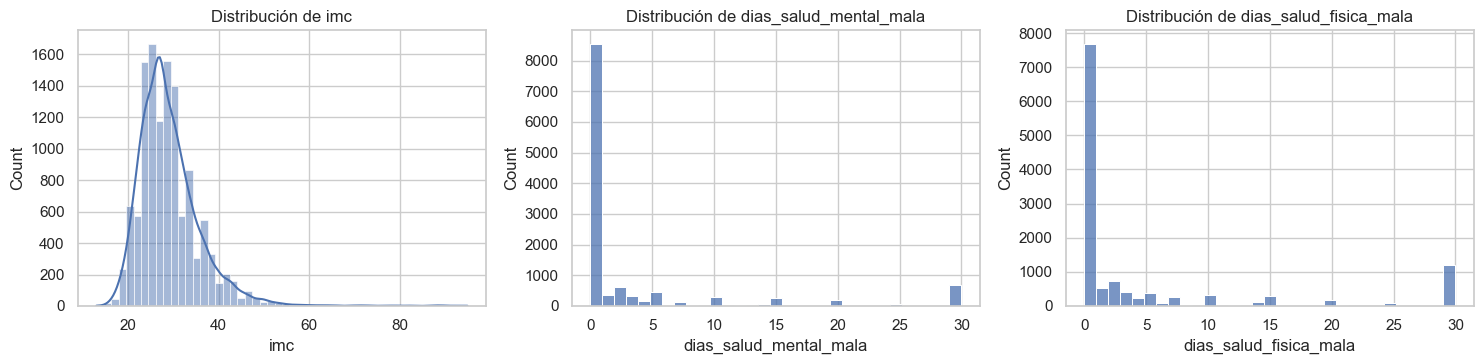

In [22]:
# Histogramas de las numéricas (31 barras en los días, una por cada valor de 0 a 30)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, NUMERICAS):
    sns.histplot(df[c], bins=31 if "dias" in c else 50, kde=(c == "imc"), ax=ax)
    ax.set_title(f"Distribución de {c}")
plt.tight_layout()
plt.show()

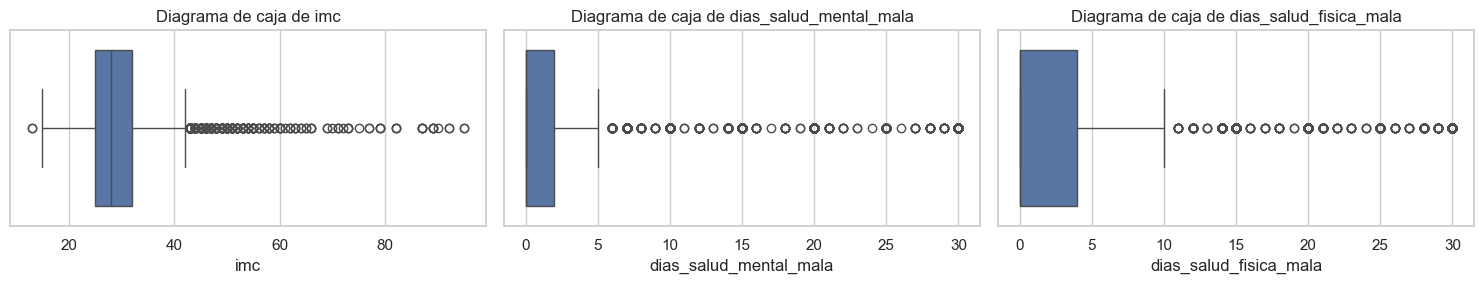

In [23]:
# Diagramas de caja de las numéricas
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, c in zip(axes, NUMERICAS):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(f"Diagrama de caja de {c}")
plt.tight_layout()
plt.show()

- El **IMC** tiene forma de campana con una cola larga a la derecha. Los valores vienen redondeados a entero.
- Los **días de mala salud** tienen dos picos, uno enorme en 0 y otro en 30, y los valores intermedios se agrupan en números "redondos" (5, 10, 15, 20). Esto indica que la gente responde de memoria y redondea, así que el dato tiene ruido de por sí. En el diagrama de caja de los días casi todo lo que no es 0 sale como "atípico", lo que deja claro que el criterio del IQR no tiene sentido para estas variables (lo vuelvo a comentar en el apartado 6).

### 3.2 Variables binarias

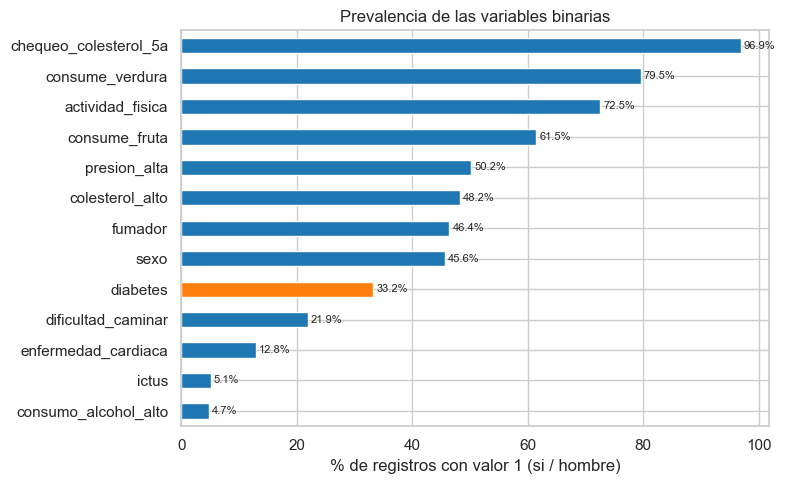

In [24]:
# Gráfico de barras con la prevalencia de cada binaria (la diabetes en naranja)
prev = (df[BINARIAS + [OBJ_CLF]].astype(float).mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
prev.plot.barh(ax=ax, color=["tab:orange" if c == OBJ_CLF else "tab:blue" for c in prev.index])
ax.set_xlabel("% de registros con valor 1 (si / hombre)")
ax.set_title("Prevalencia de las variables binarias")
# Escribo el porcentaje al lado de cada barra
for i, v in enumerate(prev):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Algunas binarias están muy desbalanceadas (`chequeo_colesterol_5a`, `consumo_alcohol_alto`, `ictus`). Puede que `ictus` o `enfermedad_cardiaca`, aunque sean poco frecuentes, estén muy ligadas a los objetivos cuando aparecen. Lo veremos en el apartado 4.

### 3.3 Variables ordinales

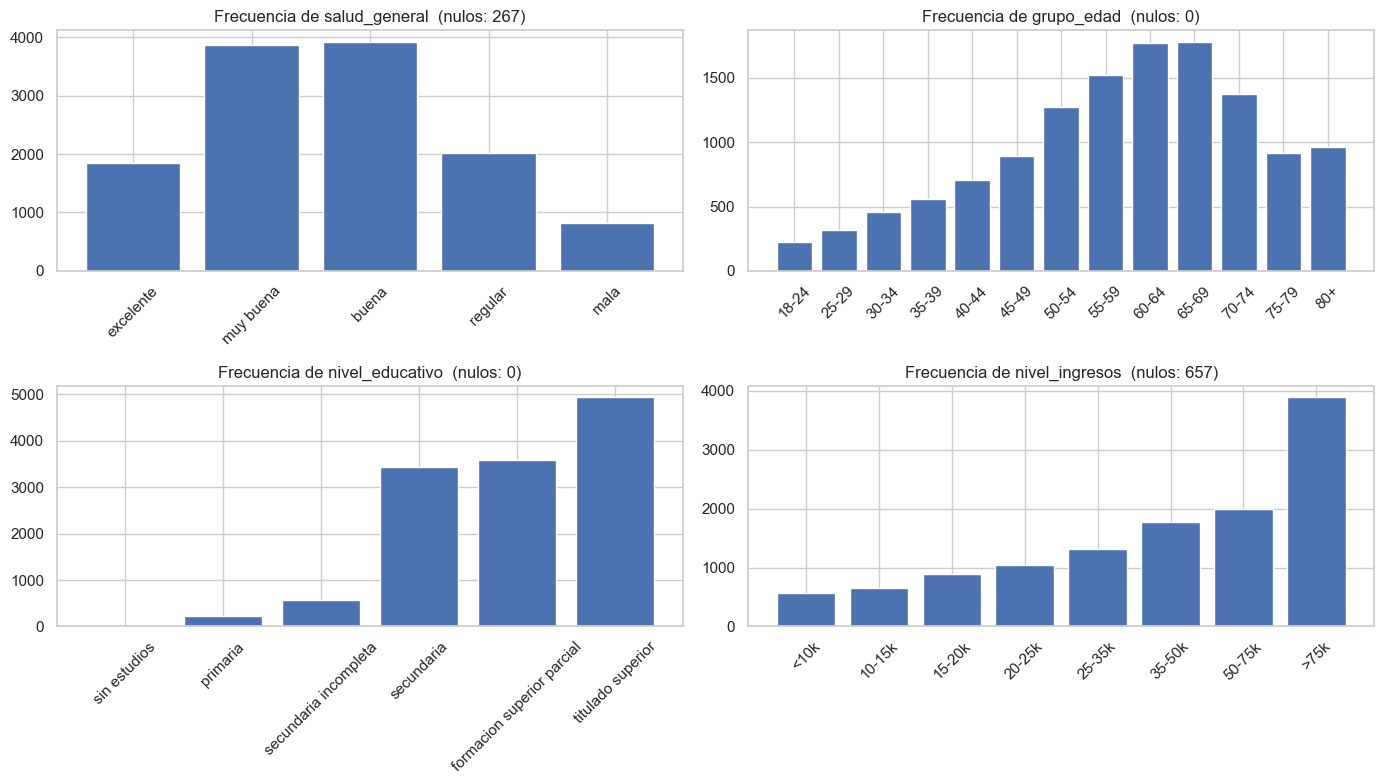

In [25]:
# Un gráfico de barras por ordinal, con las categorías en su orden y el nº de nulos en el título
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.ravel(), ORD):
    cnt = df[c].value_counts().sort_index()
    ax.bar([ORDINALES[c][int(i) - 1] for i in cnt.index], cnt.values)
    ax.set_title(f"Frecuencia de {c}  (nulos: {df[c].isna().sum()})")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

- **Edad**: la muestra está muy cargada hacia edades altas, con el grueso entre 50 y 74 años. Seguramente es consecuencia de haber sobremuestreado a los diabéticos, que suelen ser más mayores.
- **Nivel educativo**: casi todo es secundaria o superior. `sin estudios` tiene solo 7 casos y `primaria` unos 230, así que si se usa one-hot convendría agruparlas.
- **Ingresos**: la categoría más frecuente es `>75k`, con lo que la muestra parece de un nivel socioeconómico medio-alto.
- **Salud general**: la mayoría se valora como buena o muy buena, aunque hay unos 800 registros con salud `mala`.

## 4. Relaciones entre variables

Este es el apartado más largo, porque tenemos dos variables objetivo y además hay que ver cómo se relacionan las variables entre sí. Aparte de la matriz de correlación de la PLD1, uso algunas medidas extra que van mejor con variables binarias y ordinales:

- **V de Cramér** (entre 0 y 1): la asociación entre dos categóricas, calculada a partir del test chi-cuadrado.
- **Correlación de Spearman**: igual que la de Pearson pero con los rangos, así que sirve para ordinales y no le afectan los atípicos.
- **Tests de Mann-Whitney y Kruskal-Wallis**: comparan la distribución de una variable numérica entre grupos sin suponer que sea normal.
- **Información mutua**: cuánta información aporta una variable sobre el objetivo, y capta también relaciones no lineales.

### 4.1 Relación con `diabetes`

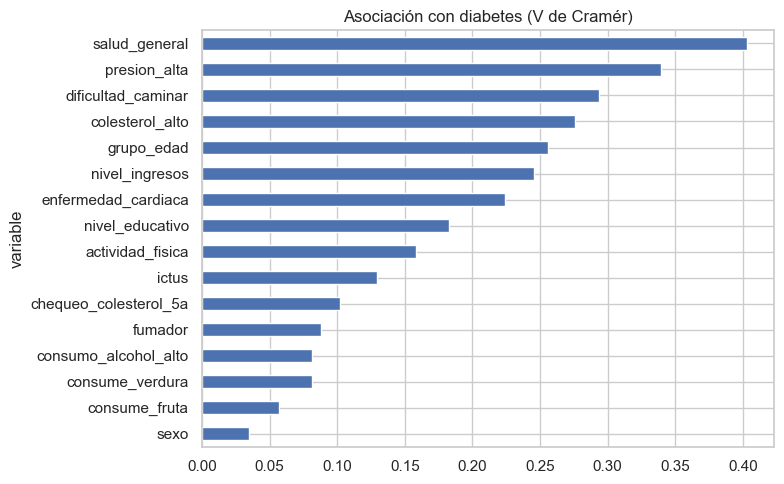

,V_cramer,p_valor
variable,,
salud_general,0.4029,0.0000
presion_alta,0.3395,0.0000
dificultad_caminar,0.2939,0.0000
colesterol_alto,0.2761,0.0000
grupo_edad,0.2558,0.0000
nivel_ingresos,0.2455,0.0000
enfermedad_cardiaca,0.2239,0.0000
nivel_educativo,0.1826,0.0000
actividad_fisica,0.1579,0.0000


In [26]:
# V de Cramér de cada binaria y ordinal con la diabetes
filas = []
for c in BINARIAS + ORD:
    sub = df[[c, OBJ_CLF]].dropna()
    v, p = cramers_v(sub[c], sub[OBJ_CLF])
    filas.append({"variable": c, "V_cramer": v, "p_valor": p})
asoc_clf = pd.DataFrame(filas).set_index("variable").sort_values("V_cramer", ascending=False)

# Gráfico de barras ordenado de menor a mayor asociación
fig, ax = plt.subplots(figsize=(8, 5))
asoc_clf["V_cramer"].sort_values().plot.barh(ax=ax)
ax.set_title("Asociación con diabetes (V de Cramér)")
plt.tight_layout()
plt.show()
asoc_clf.round(4)

In [27]:
# % de diabéticos según el valor de cada binaria, y la diferencia entre los dos grupos
tasa_bin = pd.DataFrame({c: df.groupby(c)[OBJ_CLF].mean() * 100 for c in BINARIAS}).T
tasa_bin.columns = ["% diabetes si=0", "% diabetes si=1"]
tasa_bin["diferencia"] = tasa_bin.iloc[:, 1] - tasa_bin.iloc[:, 0]
tasa_bin.astype(float).sort_values("diferencia", ascending=False).round(1)

,% diabetes si=0,% diabetes si=1,diferencia
dificultad_caminar,25.8,59.3,33.5
presion_alta,17.2,49.2,32.0
enfermedad_cardiaca,29.2,60.8,31.6
ictus,31.8,59.7,27.9
chequeo_colesterol_5a,6.3,34.1,27.8
colesterol_alto,20.7,46.7,26.0
fumador,29.3,37.6,8.3
sexo,31.7,35.0,3.3
consume_fruta,36.5,31.0,-5.5
consume_verdura,40.8,31.3,-9.5


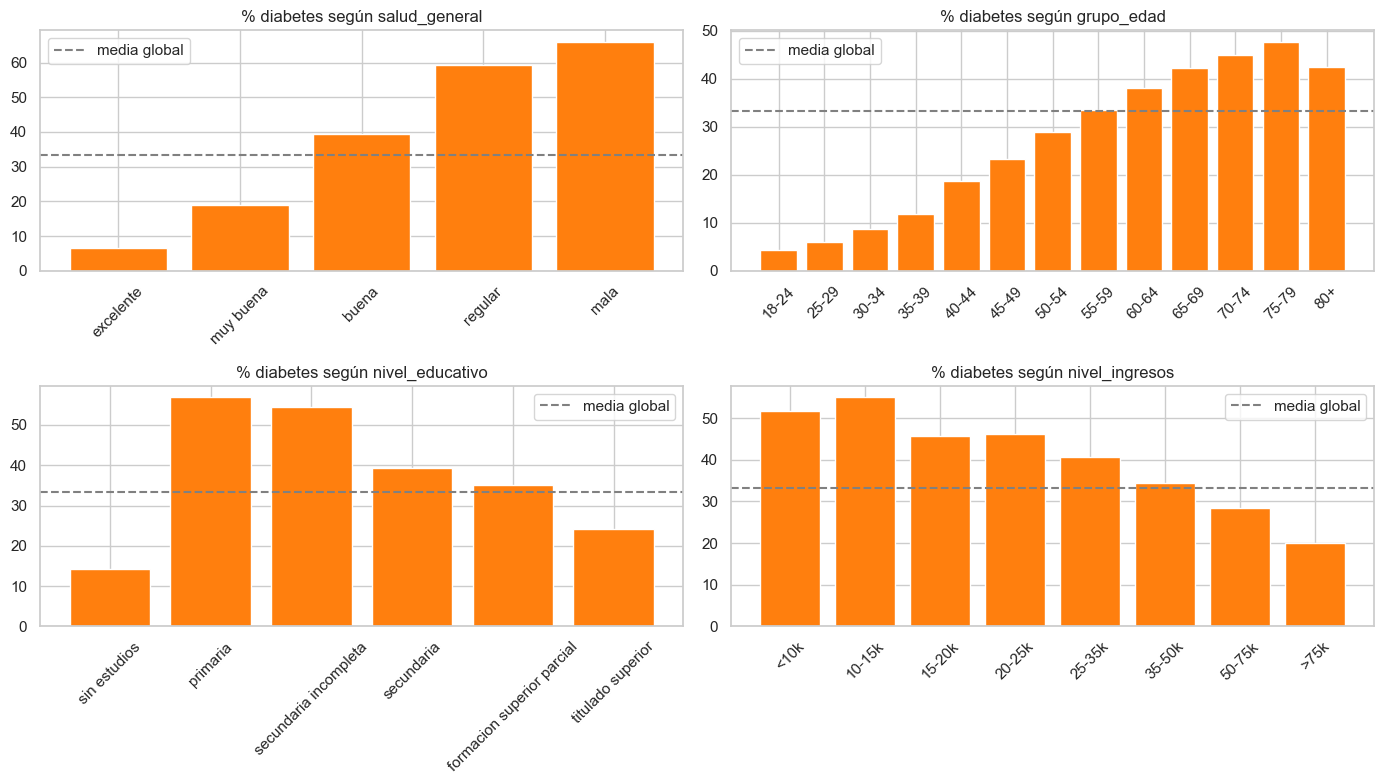

In [28]:
# % de diabéticos en cada categoría de las ordinales, con la media global como referencia
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
base = df[OBJ_CLF].mean() * 100
for ax, c in zip(axes.ravel(), ORD):
    t = df.groupby(c)[OBJ_CLF].mean() * 100
    ax.bar([ORDINALES[c][int(i) - 1] for i in t.index], t.values, color="tab:orange")
    ax.axhline(base, ls="--", c="gray", label="media global")
    ax.set_title(f"% diabetes según {c}")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

Lo más importante que se ve aquí es que hay variables con una relación muy clara y con gradiente con la diabetes:

- **Salud general** es la que más se asocia: la tasa de diabetes sube de forma casi lineal desde `excelente` hasta `mala`.
- **Presión alta** y **colesterol alto** también pesan mucho, porque entre quien los tiene la proporción de diabéticos es mucho mayor. Son los factores de riesgo metabólico clásicos, así que cuadra.
- **Edad**: la tasa sube de forma continua con la edad, desde un 4 % en 18-24 hasta casi un 48 % en 75-79, y baja un poco en 80+ (seguramente porque a esas edades sobreviven más los que no tienen la enfermedad).
- **Ingresos y nivel educativo**: relación inversa, a menos ingresos y estudios, más diabetes. La categoría `sin estudios` se sale del patrón, pero con 7 casos no significa nada.
- **Dificultad para caminar** y **enfermedad cardíaca** también se asocian bastante.
- En cambio **sexo**, **consumo de verdura** o **fumador** apenas aportan por sí solas. El **consumo de alcohol alto** tiene relación inversa (los que beben mucho tienen menos diabetes en la muestra), algo que ya se ha visto en otros estudios con este tipo de encuestas y que seguramente esconde efectos de otras variables.

Al ser relaciones monótonas, codificar las ordinales como números enteros (en vez de one-hot) tiene sentido y simplifica los modelos.

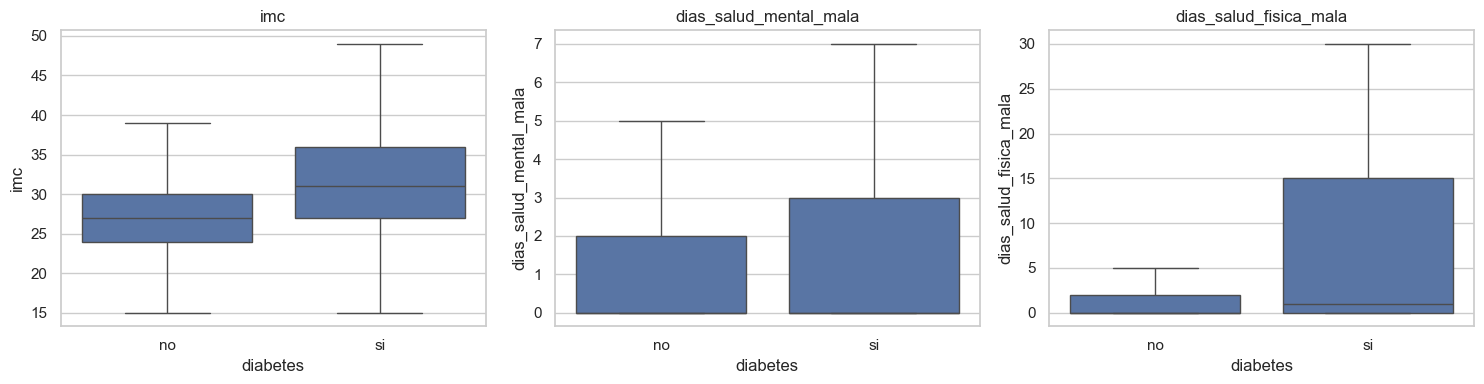

imc                       mediana no= 27.0  si= 31.0  | media no=27.76  si=31.88  | p=2.19e-249
dias_salud_mental_mala    mediana no=  0.0  si=  0.0  | media no= 2.84  si= 4.59  | p=7.89e-13
dias_salud_fisica_mala    mediana no=  0.0  si=  1.0  | media no= 3.47  si= 8.01  | p=8.14e-137


In [29]:
# Las numéricas frente a la diabetes: diagramas de caja sin los atípicos para que se vea la caja
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, NUMERICAS):
    sns.boxplot(x=df[OBJ_CLF].map({0: "no", 1: "si"}), y=df[c], ax=ax, showfliers=False)
    ax.set_title(c)
    ax.set_xlabel("diabetes")
plt.tight_layout()
plt.show()

# Medianas, medias y test de Mann-Whitney para cada numérica
for c in NUMERICAS:
    a, b = [g[c].dropna() for _, g in df.groupby(OBJ_CLF)]
    u = stats.mannwhitneyu(a, b)
    print(f"{c:<25} mediana no={a.median():5.1f}  si={b.median():5.1f}  | "
          f"media no={a.mean():5.2f}  si={b.mean():5.2f}  | p={u.pvalue:.2e}")

In [30]:
# IMC agrupado por las categorías de la OMS, que es más fácil de explicar a un sanitario
cat_imc = pd.cut(df["imc"], [0, 18.5, 25, 30, 35, 40, 100],
                 labels=["bajo peso", "normal", "sobrepeso", "obesidad I", "obesidad II", "obesidad III"])
t = df.groupby(cat_imc, observed=True)[OBJ_CLF].agg(["mean", "size"])
t["mean"] = (t["mean"].astype(float) * 100).round(1)
t.columns = ["% diabetes", "n"]
t

,% diabetes,n
imc,,
bajo peso,14.5,145
normal,17.5,3675
sobrepeso,30.6,4426
obesidad I,44.3,2364
obesidad II,56.5,1026
obesidad III,61.9,717


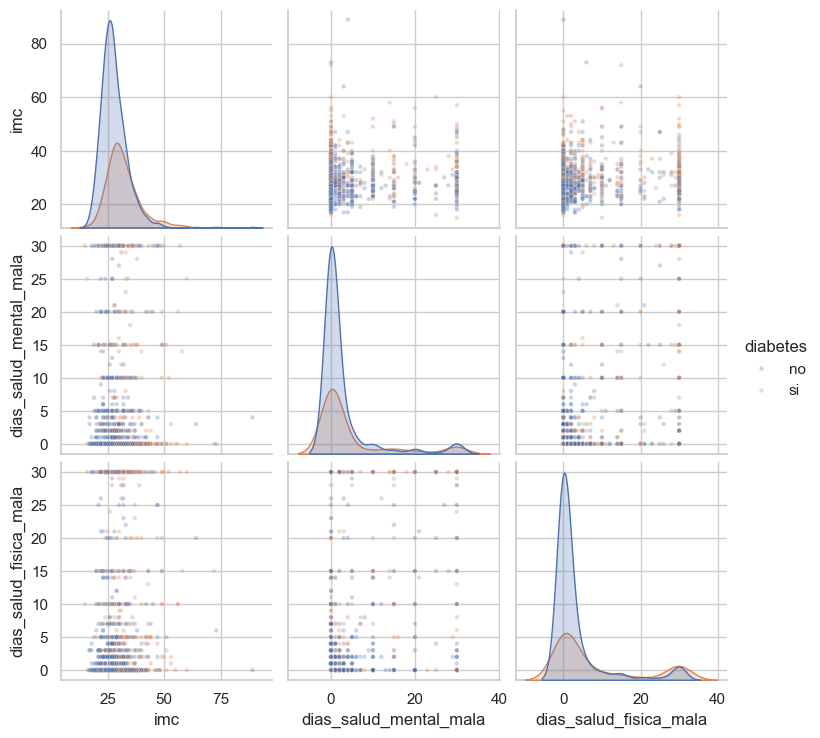

In [31]:
# Matriz de dispersión como la de la PLD1, con una muestra para que no tarde ni se sature el gráfico
muestra = df[NUMERICAS + [OBJ_CLF]].dropna().sample(1500, random_state=SEMILLA).astype(float)
muestra[OBJ_CLF] = muestra[OBJ_CLF].map({0: "no", 1: "si"})
sns.pairplot(muestra, hue=OBJ_CLF, plot_kws={"alpha": 0.3, "s": 10}, diag_kind="kde")
plt.show()

El **IMC** es claramente mayor en diabéticos (mediana de 31 frente a 27) y, agrupado por las categorías de la OMS, el porcentaje de diabetes sube escalón a escalón con el peso: del 17 % en peso normal al 62 % en obesidad III. Es una de las variables más útiles para clasificación. Los días de mala salud física y mental también son mayores en diabéticos, aunque aquí la relación es más una consecuencia (la diabetes empeora la salud) que una causa. En la matriz de dispersión no se ve ninguna separación clara entre los dos grupos usando solo estas tres variables, lo cual es normal porque los conteos de días tienen muy pocos valores distintos.

### 4.2 Relación con `dias_salud_fisica_mala`

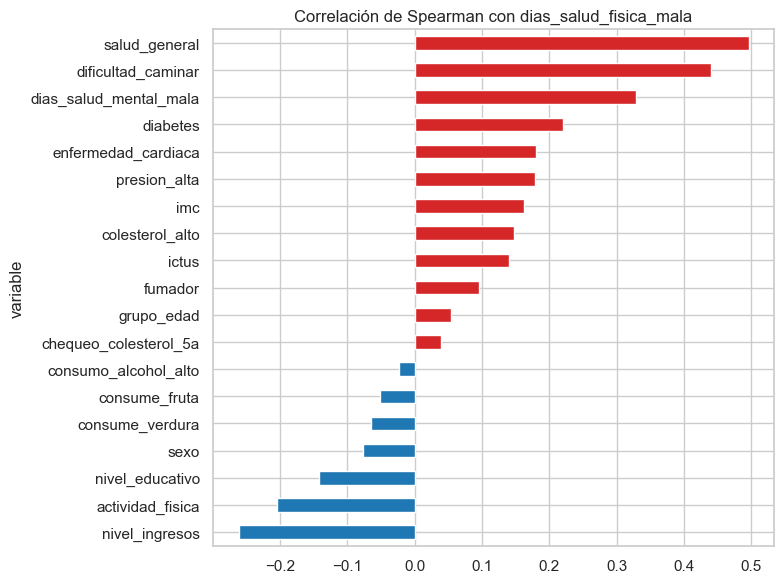

,spearman,p_valor
variable,,
salud_general,0.4960,0.0000
dificultad_caminar,0.4403,0.0000
dias_salud_mental_mala,0.3294,0.0000
nivel_ingresos,-0.2618,0.0000
diabetes,0.2205,0.0000
actividad_fisica,-0.2042,0.0000
enfermedad_cardiaca,0.1801,0.0000
presion_alta,0.1784,0.0000
imc,0.1619,0.0000


In [32]:
# Spearman de cada variable con los días de mala salud física
filas = []
for c in [x for x in df.columns if x != OBJ_REG]:
    sub = df[[c, OBJ_REG]].dropna().astype(float)
    rho, p = stats.spearmanr(sub[c], sub[OBJ_REG])
    filas.append({"variable": c, "spearman": rho, "p_valor": p})
asoc_reg = pd.DataFrame(filas).set_index("variable").sort_values("spearman", key=abs, ascending=False)

# En rojo las correlaciones positivas y en azul las negativas
orden = asoc_reg["spearman"].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
orden.plot.barh(ax=ax, color=np.where(orden > 0, "tab:red", "tab:blue"))
ax.set_title("Correlación de Spearman con dias_salud_fisica_mala")
plt.tight_layout()
plt.show()
asoc_reg.round(4)

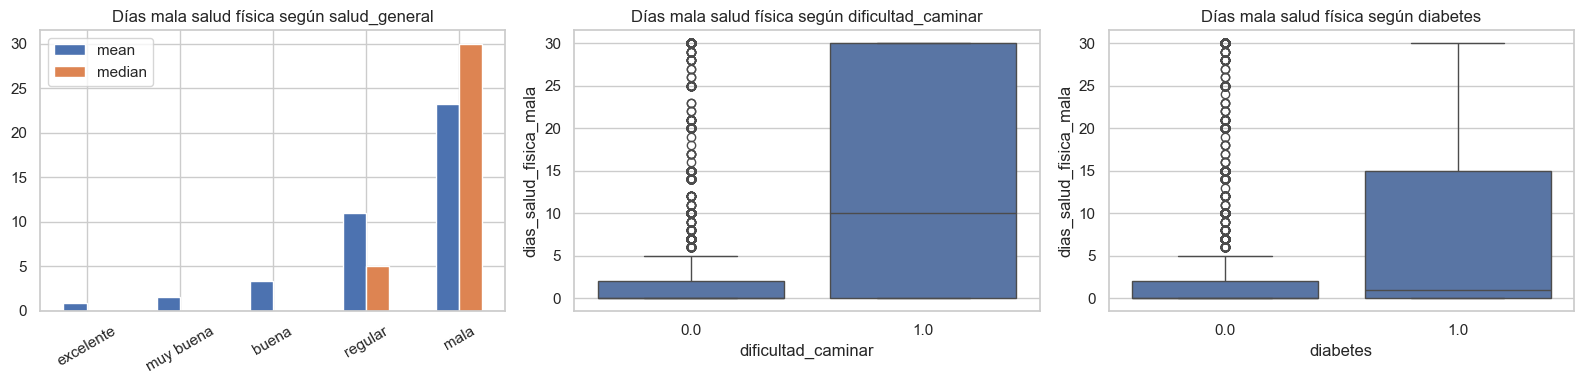

,pct_cero,pct_30,media
excelente,85.0,1.1,0.9
muy buena,74.7,1.7,1.6
buena,61.7,4.6,3.4
regular,29.2,20.1,11.0
mala,6.5,60.8,23.3


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Media y mediana de días según la salud general
g = df.groupby("salud_general")[OBJ_REG].agg(["mean", "median"])
g.index = [ORDEN_SALUD[int(i) - 1] for i in g.index]
g.plot.bar(ax=axes[0], rot=30)
axes[0].set_title("Días mala salud física según salud_general")

# Diagramas de caja según dificultad para caminar y diabetes
for ax, c in zip(axes[1:], ["dificultad_caminar", "diabetes"]):
    sns.boxplot(x=df[c].astype(float), y=df[OBJ_REG], ax=ax)
    ax.set_title(f"Días mala salud física según {c}")
plt.tight_layout()
plt.show()

# Proporción de ceros y de treintas en cada nivel de salud general
t = df.groupby("salud_general")[OBJ_REG].agg(pct_cero=lambda s: (s == 0).mean() * 100,
                                              pct_30=lambda s: (s == 30).mean() * 100,
                                              media="mean")
t.index = [ORDEN_SALUD[int(i) - 1] for i in t.index]
t.round(1)

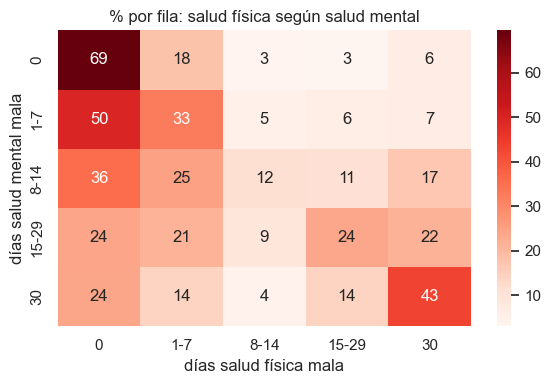

In [34]:
# Relación entre los dos conteos de días, agrupados por tramos
tramos = [-1, 0, 7, 14, 29, 30]
etiquetas = ["0", "1-7", "8-14", "15-29", "30"]
ct = pd.crosstab(pd.cut(df["dias_salud_mental_mala"], tramos, labels=etiquetas),
                 pd.cut(df[OBJ_REG], tramos, labels=etiquetas),
                 normalize="index") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Reds")
plt.xlabel("días salud física mala")
plt.ylabel("días salud mental mala")
plt.title("% por fila: salud física según salud mental")
plt.tight_layout()
plt.show()

Para la regresión, la variable que más explica con diferencia es **`salud_general`**. Quien se valora con salud `mala` declara de media unos 23 días de mala salud física, frente a menos de 1 día de quien dice tener salud `excelente`, y la proporción de ceros pasa del 85 % al 6,5 %. Detrás vienen **`dificultad_caminar`** y **`dias_salud_mental_mala`** (la salud física y mental van muy de la mano: quien tiene 30 días malos de una tiene muchas papeletas de tener muchos de la otra), y luego los ingresos, la diabetes, la actividad física y la enfermedad cardíaca.

Las relaciones son claras pero de intensidad moderada (ninguna pasa de 0,5), así que es de esperar que el modelo de regresión tenga un error considerable. Es lógico, porque el número de días depende de muchas cosas que la encuesta no recoge (una gripe, una lesión...).

### 4.3 Matriz de correlación

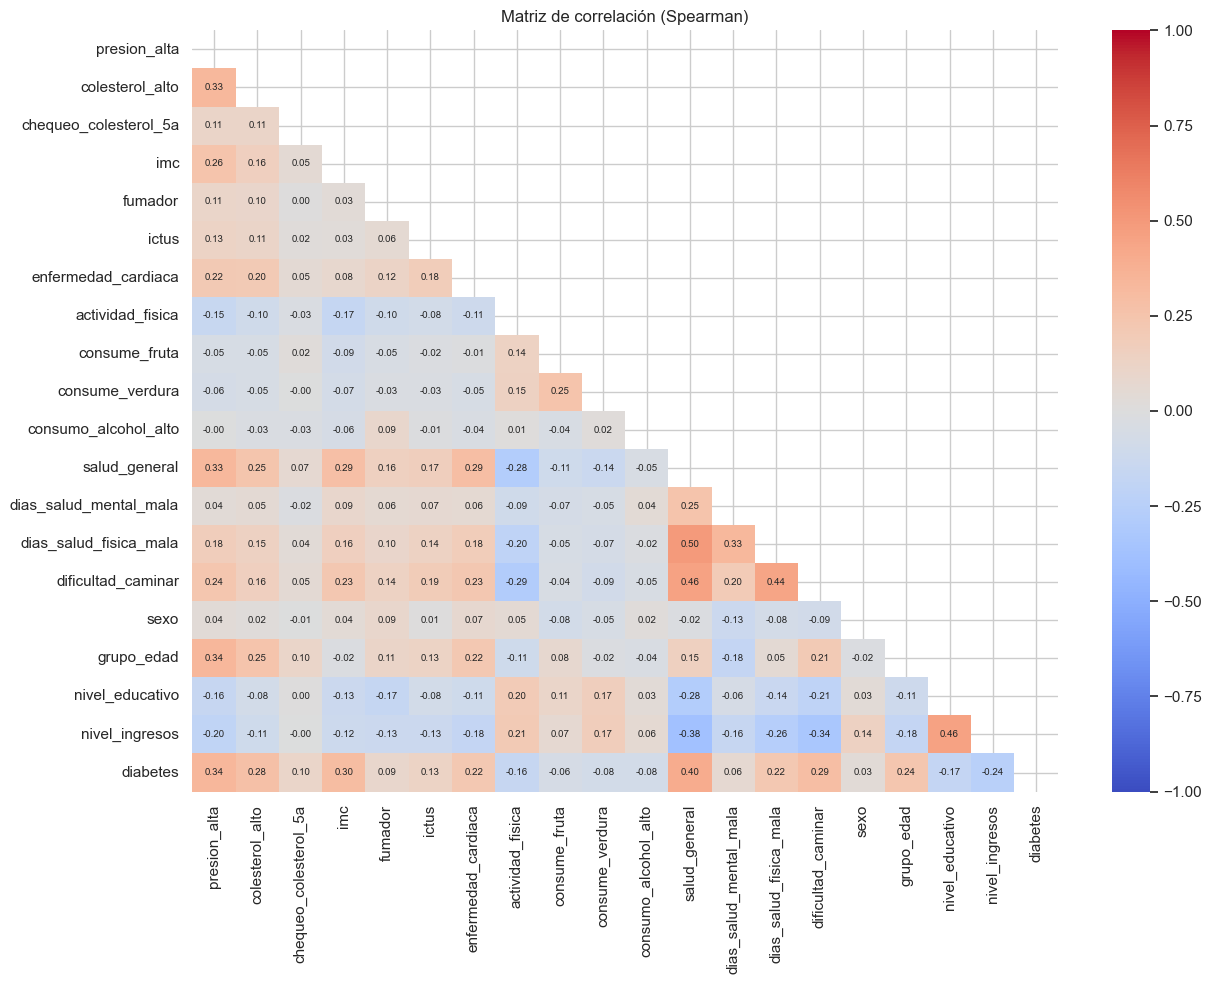

,level_0,level_1,rho
89,dias_salud_fisica_mala,salud_general,0.496
170,nivel_ingresos,nivel_educativo,0.458
102,dificultad_caminar,salud_general,0.456
104,dificultad_caminar,dias_salud_fisica_mala,0.440
182,diabetes,salud_general,0.401
164,nivel_ingresos,salud_general,-0.382
120,grupo_edad,presion_alta,0.340
171,diabetes,presion_alta,0.340
167,nivel_ingresos,dificultad_caminar,-0.336
0,colesterol_alto,presion_alta,0.330


In [35]:
# Matriz de correlación de Spearman entre todas las variables (con la mitad de arriba oculta porque es simétrica)
corr = df.astype(float).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title("Matriz de correlación (Spearman)")
plt.tight_layout()
plt.show()

# Las 10 parejas más correladas, para vigilar la multicolinealidad
pares = corr.where(~mask).stack().rename("rho").reset_index()
pares = pares.reindex(pares["rho"].abs().sort_values(ascending=False).index)
pares.head(10).round(3)

No hay ninguna pareja de variables tan correlada como para que una sobre (ninguna pasa de 0,5 en valor absoluto), así que la multicolinealidad no es un problema serio. Las relaciones más fuertes forman un bloque de **"estado de salud"** (`salud_general`, `dias_salud_fisica_mala`, `dificultad_caminar`, `dias_salud_mental_mala`) y otro **socioeconómico** (`nivel_ingresos` y `nivel_educativo`). Además, los ingresos se relacionan negativamente con todo el bloque de mala salud. Para modelos lineales con regularización esto no supone problema, y si se quisiera un modelo muy interpretable se podría quedar una variable por bloque.

### 4.4 Información mutua

La correlación solo ve relaciones monótonas, así que la complemento con la información mutua, que también capta relaciones no lineales.

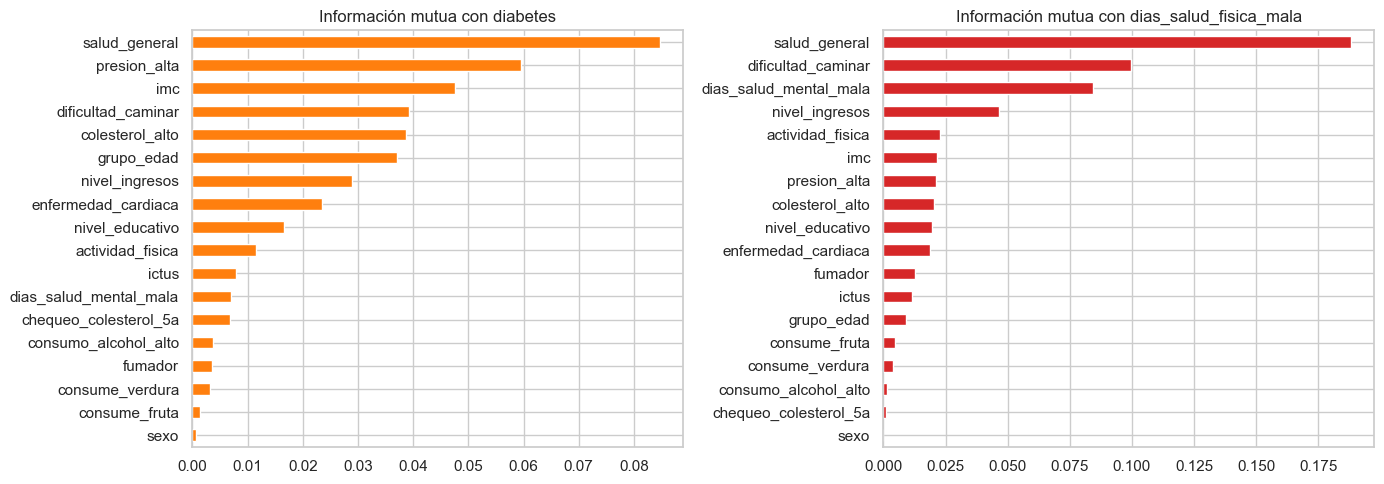

In [36]:
# Variables de entrada sin los dos objetivos. Para poder calcular la información mutua relleno
# los nulos con la mediana (es solo para este análisis, no es la imputación definitiva)
X_mi = df.drop(columns=[OBJ_CLF, OBJ_REG]).astype(float)
X_mi = X_mi.fillna(X_mi.median())

# Le digo cuáles son discretas: todas menos el IMC
discretas = [c != "imc" for c in X_mi.columns]

# Información mutua con cada objetivo
mi_clf = pd.Series(mutual_info_classif(X_mi, df[OBJ_CLF].astype(int), discrete_features=discretas,
                                       random_state=SEMILLA), index=X_mi.columns)
mi_reg = pd.Series(mutual_info_regression(X_mi, df[OBJ_REG], discrete_features=discretas,
                                          random_state=SEMILLA), index=X_mi.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mi_clf.sort_values().plot.barh(ax=axes[0], color="tab:orange")
axes[0].set_title("Información mutua con diabetes")
mi_reg.sort_values().plot.barh(ax=axes[1], color="tab:red")
axes[1].set_title("Información mutua con dias_salud_fisica_mala")
plt.tight_layout()
plt.show()

La información mutua confirma el ranking que ya se intuía con las otras medidas. Para **diabetes** destacan `salud_general`, `presion_alta`, `imc`, `dificultad_caminar`, `colesterol_alto` y `grupo_edad`. Para los **días de mala salud física**, `salud_general`, `dificultad_caminar` y `dias_salud_mental_mala`. En los dos casos hay un grupo de variables con aportación casi nula (`sexo`, `consume_fruta`, `consume_verdura`, `consumo_alcohol_alto`...) que serían las primeras candidatas a descartar si hiciera falta reducir variables, aunque con modelos de árboles o regularizados se pueden dejar y que el propio modelo decida.

### 4.5 Interacciones entre los principales factores de riesgo

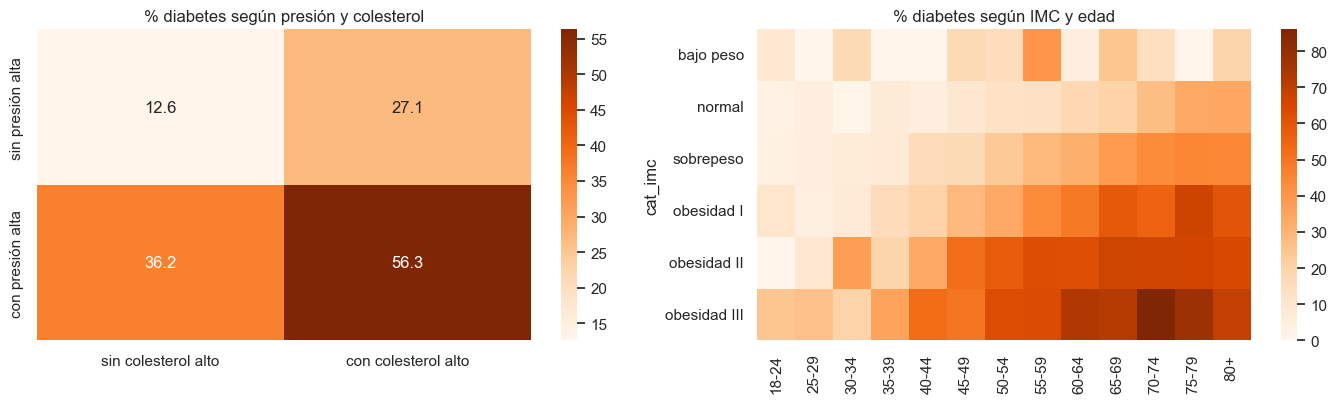

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# % de diabetes combinando presión alta y colesterol alto
piv = df.pivot_table(index="presion_alta", columns="colesterol_alto", values=OBJ_CLF,
                     aggfunc="mean").astype(float) * 100
piv.index = ["sin presión alta", "con presión alta"]
piv.columns = ["sin colesterol alto", "con colesterol alto"]
sns.heatmap(piv, annot=True, fmt=".1f", cmap="Oranges", ax=axes[0])
axes[0].set_title("% diabetes según presión y colesterol")

# % de diabetes combinando categoría de IMC y grupo de edad
piv2 = df.assign(cat_imc=cat_imc).pivot_table(index="cat_imc", columns="grupo_edad", values=OBJ_CLF,
                                              aggfunc="mean", observed=True).astype(float) * 100
piv2.columns = [ORDEN_EDAD[int(i) - 1] for i in piv2.columns]
sns.heatmap(piv2, cmap="Oranges", ax=axes[1])
axes[1].set_title("% diabetes según IMC y edad")
plt.tight_layout()
plt.show()

Los factores de riesgo se acumulan: con presión y colesterol altos a la vez el porcentaje de diabetes se dispara frente a quien no tiene ninguno de los dos, y en el mapa de IMC × edad se ve que la combinación de obesidad y edad avanzada es la zona de mayor riesgo. Esto apunta a que los modelos que captan interacciones (árboles, boosting) pueden sacar algo más que una regresión logística simple, aunque la logística también recogerá bastante porque los efectos son en gran parte aditivos.

## 5. Análisis de valores perdidos

In [38]:
# Nº y % de nulos por columna, como en la PLD1
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})

,nulos,%
nivel_ingresos,657,5.15
imc,397,3.11
dias_salud_mental_mala,397,3.11
fumador,376,2.95
consume_fruta,376,2.95
actividad_fisica,376,2.95
dificultad_caminar,376,2.95
salud_general,267,2.09


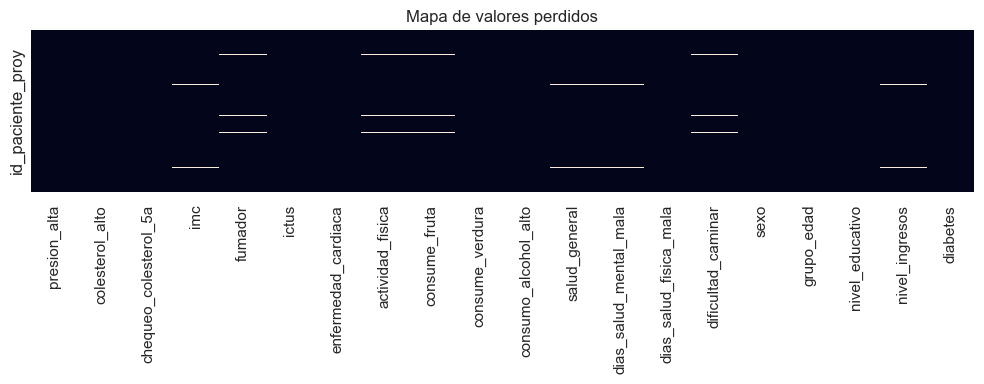

In [39]:
# Mapa de valores perdidos de la PLD1: cada línea blanca es una fila con ese dato ausente
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Mapa de valores perdidos")
plt.tight_layout()
plt.show()

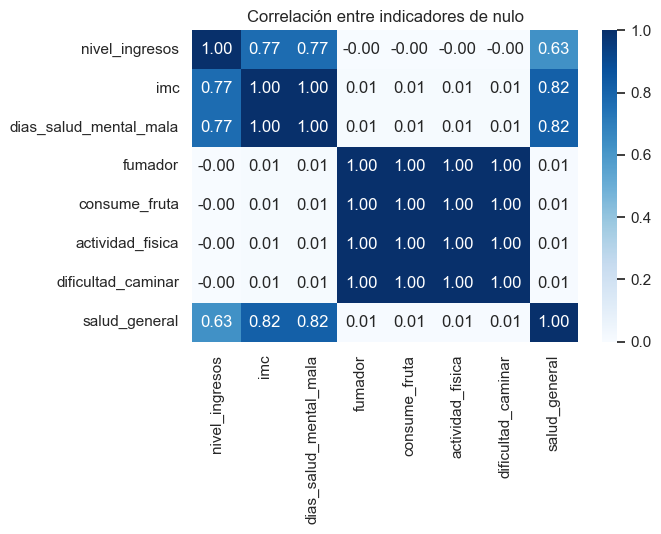

Nº de columnas con nulo por fila:
0    11735
1      257
3      125
4      615
5        3
7        5
8       10
Name: count, dtype: int64


In [40]:
# ¿Faltan juntas algunas columnas? Correlación entre los indicadores de nulo (1 = falta)
m = df[nulos.index].isnull().astype(int)
plt.figure(figsize=(7, 5.5))
sns.heatmap(m.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlación entre indicadores de nulo")
plt.tight_layout()
plt.show()

# Cuántas filas tienen 0, 1, 2... columnas con nulo
print("Nº de columnas con nulo por fila:")
print(m.sum(axis=1).value_counts().sort_index())

Es interesante ver cómo los nulos no están repartidos al azar sino en **bloques**:

- `fumador`, `actividad_fisica`, `consume_fruta` y `dificultad_caminar` faltan siempre a la vez (376 filas). Son justo las cuatro columnas con codificaciones mezcladas, así que parece un bloque de la encuesta que en algunos registros no se cargó.
- `imc` y `dias_salud_mental_mala` también faltan siempre juntos (397 filas).
- `salud_general` (267) y `nivel_ingresos` (657) van por libre. Lo de los ingresos es lo esperable, es la típica pregunta que la gente prefiere no contestar.

Ninguna columna pasa del 5,2 % de nulos, así que no hay motivo para eliminar columnas. Por otro lado, eliminar todas las filas con algún nulo nos haría perder unas 1.000 filas, por lo que es mejor imputar. Antes compruebo si el hecho de faltar el dato tiene relación con los objetivos, porque si la tiene merece la pena añadir un indicador de nulo.

In [41]:
# Para cada columna con nulos comparo los objetivos entre las filas donde falta y donde no
filas = []
for c in nulos.index:
    falta = df[c].isna()
    filas.append({
        "columna": c,
        "%diabetes_si_falta": df.loc[falta, OBJ_CLF].mean() * 100,
        "%diabetes_no_falta": df.loc[~falta, OBJ_CLF].mean() * 100,
        "p_chi2_diabetes": stats.chi2_contingency(pd.crosstab(falta, df[OBJ_CLF]))[1],
        "media_dias_fis_si_falta": df.loc[falta, OBJ_REG].mean(),
        "media_dias_fis_no_falta": df.loc[~falta, OBJ_REG].mean(),
        "p_MW_dias_fis": stats.mannwhitneyu(df.loc[falta, OBJ_REG], df.loc[~falta, OBJ_REG]).pvalue,
    })
pd.DataFrame(filas).set_index("columna").astype(float).round(3)

,%diabetes_si_falta,%diabetes_no_falta,p_chi2_diabetes,media_dias_fis_si_falta,media_dias_fis_no_falta,p_MW_dias_fis
columna,,,,,,
nivel_ingresos,34.247,33.184,0.603,4.769,4.991,0.252
imc,36.776,33.126,0.143,4.839,4.984,0.745
dias_salud_mental_mala,36.776,33.126,0.143,4.839,4.984,0.745
fumador,36.968,33.126,0.133,5.782,4.955,0.705
consume_fruta,36.968,33.126,0.133,5.782,4.955,0.705
actividad_fisica,36.968,33.126,0.133,5.782,4.955,0.705
dificultad_caminar,36.968,33.126,0.133,5.782,4.955,0.705
salud_general,38.202,33.133,0.094,4.221,4.996,0.261


En ninguna columna el hecho de que falte el dato cambia de forma significativa la tasa de diabetes ni los días de mala salud física (todos los p-valores están por encima de 0,05). En las filas con nulos hay un poco más de diabéticos (36-38 % frente a 33 %), pero la diferencia no es significativa. Por tanto, los nulos parecen **aleatorios respecto a los objetivos** (fallos de carga más que pacientes "especiales").

**Tratamiento propuesto:**
- No eliminar ni columnas ni filas.
- Imputar dentro del `Pipeline` de cada línea de trabajo: la mediana para `imc` y `dias_salud_mental_mala`, la moda para las binarias y ordinales, o probar un `KNNImputer` que aproveche la relación entre variables.
- Ajustar el imputador **solo con el conjunto de entrenamiento**, para no meter información del test.
- Añadir indicadores de nulo es opcional. Se puede probar, pero no espero que aporte mucho.

## 6. Análisis de valores atípicos

In [42]:
def iqr_outliers(series):
    """Devuelve los valores fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR], igual que en la PLD1."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]


# Nº de atípicos por el criterio IQR en cada numérica
for col in NUMERICAS:
    outliers = iqr_outliers(df[col].dropna())
    print(f"{col}: {len(outliers)} valores atípicos ({len(outliers) / df[col].notna().sum() * 100:.1f}%)")

imc: 516 valores atípicos (4.2%)
dias_salud_mental_mala: 1849 valores atípicos (15.0%)
dias_salud_fisica_mala: 2058 valores atípicos (16.1%)


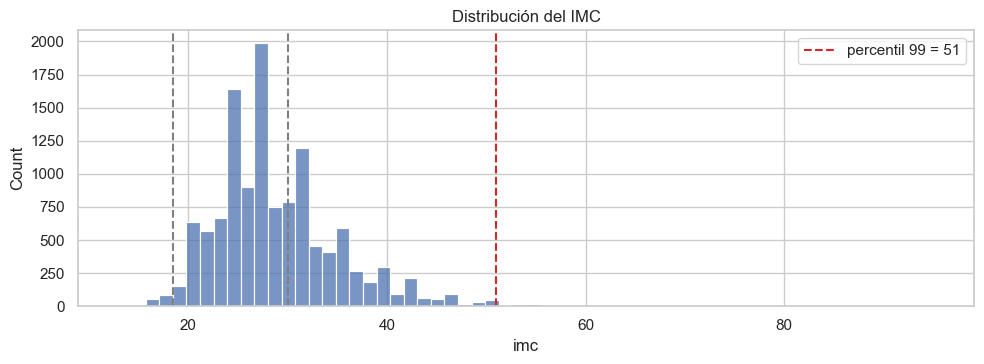

IMC: min=13.0, max=95.0
IMC > 60: 46  |  IMC < 15: 2  |  IMC > p99: 109
¿IMC siempre entero? True


In [43]:
# Detalle del IMC: histograma con las líneas de 18,5 (bajo peso) y 30 (obesidad)
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(df["imc"], bins=60, ax=ax)
ax.axvline(18.5, ls="--", c="gray")
ax.axvline(30, ls="--", c="gray")
p99 = df["imc"].quantile(0.99)
ax.axvline(p99, ls="--", c="tab:red", label=f"percentil 99 = {p99:.0f}")
ax.set_title("Distribución del IMC")
ax.legend()
plt.tight_layout()
plt.show()

print(f"IMC: min={df['imc'].min()}, max={df['imc'].max()}")
print(f"IMC > 60: {(df['imc'] > 60).sum()}  |  IMC < 15: {(df['imc'] < 15).sum()}  |  IMC > p99: {(df['imc'] > p99).sum()}")
print("¿IMC siempre entero?", (df["imc"].dropna() % 1 == 0).all())

Aplicando el criterio del IQR salen muchos atípicos, pero hay que leerlo con cuidado:

- En los **días de mala salud** el criterio IQR no tiene sentido. Como la mediana y el primer cuartil son 0, casi cualquier valor distinto de 0 sale como atípico, y sin embargo todos están en el rango válido 0-30. Son la forma natural de la variable, no errores, así que **no se tocan**.
- En el **IMC** hay unos 500 valores por encima del límite del IQR y unos pocos llegan a 70-95, que son casos de obesidad mórbida extrema. Son muy raros pero no imposibles, así que no son errores claros.

**Tratamiento propuesto:** mantener todos los valores, pero en clustering y en los modelos sensibles a la escala (regresión lineal/logística, KNN) **recortar el IMC al percentil 99** (winsorizar), para que unos pocos casos extremos no tiren de los centroides o de los coeficientes. Los modelos de árboles no lo necesitan. El recorte también se ajusta con el train dentro del pipeline.

In [44]:
# Registro los IMC por encima del percentil 99 como atípicos extremos
registra(
    columna="imc",
    tipo_incidencia="atipico_extremo",
    n_filas_afectadas=(df["imc"] > p99).sum(),
    accion="Se mantienen; se recortan al percentil 99 en clustering y modelos sensibles a la escala.",
)

Registrada: imc / atipico_extremo (109 filas)


## 7. Análisis de las variables objetivo

### 7.1 `diabetes` (clasificación)

{np.int64(0): 8512, np.int64(1): 4238}
{np.int64(0): 66.8, np.int64(1): 33.2}


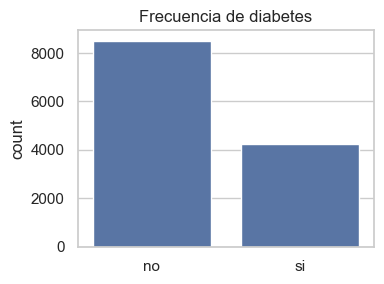

In [45]:
# Frecuencias absolutas y relativas de la diabetes
print(df[OBJ_CLF].value_counts().to_dict())
print((df[OBJ_CLF].value_counts(normalize=True) * 100).round(1).to_dict())

# Gráfico de barras
fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(x=df[OBJ_CLF].map({0: "no", 1: "si"}), ax=ax)
ax.set_title("Frecuencia de diabetes")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

Un **33 % de los registros son diabéticos**, justo lo que dice el enunciado sobre el remuestreo estratificado. Hay un desbalance moderado (2 a 1), no extremo, así que no hace falta nada agresivo tipo SMOTE, pero sí:

- usar **partición estratificada** en train/test y en la validación cruzada,
- evaluar con métricas que no se engañen con el desbalance (**ROC-AUC, F1, recall**) y no solo con accuracy,
- y, como es una herramienta de **cribado**, dar más peso al **recall** (que no se escapen diabéticos) y ajustar el umbral de decisión en vez de quedarse con el 0,5 por defecto.

Es importante dejar claro, como pide el enunciado, que **esta proporción no es la prevalencia real** de la diabetes (en la población general es bastante menor). Por eso ninguna cifra de este EDA se puede leer como un dato epidemiológico, y las probabilidades del modelo no serán probabilidades poblacionales salvo que se recalibren con la prevalencia real.

### 7.2 `dias_salud_fisica_mala` (regresión)

Media: 4.98  |  Mediana: 0  |  Desv. típica: 9.43  |  Varianza: 88.9
% ceros: 60.3%  |  % 30: 9.3%  |  % entre 1 y 29: 30.3%


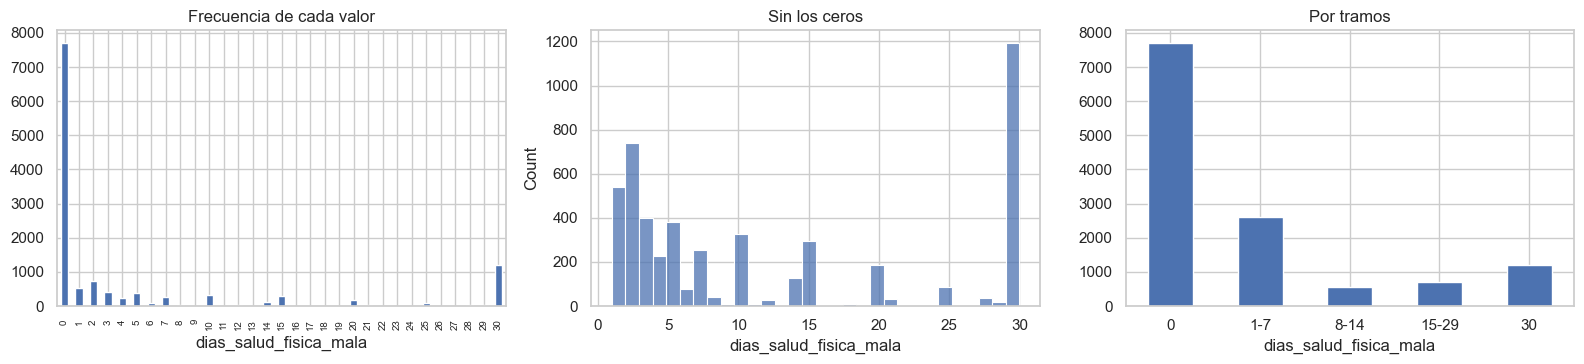

In [46]:
y = df[OBJ_REG]

# Estadísticos básicos y peso de cada pico
print(f"Media: {y.mean():.2f}  |  Mediana: {y.median():.0f}  |  Desv. típica: {y.std():.2f}  |  Varianza: {y.var():.1f}")
print(f"% ceros: {(y == 0).mean() * 100:.1f}%  |  % 30: {(y == 30).mean() * 100:.1f}%  |  "
      f"% entre 1 y 29: {((y > 0) & (y < 30)).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))

# Frecuencia de cada valor de 0 a 30
y.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Frecuencia de cada valor")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)

# Distribución quitando los ceros, para ver mejor el resto
sns.histplot(y[y > 0], bins=30, ax=axes[1])
axes[1].set_title("Sin los ceros")

# Por tramos
pd.cut(y, tramos, labels=etiquetas).value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Por tramos")
plt.tight_layout()
plt.show()

Tal y como avisaba el enunciado, esta variable no es una continua normal y corriente:

- Un **60 % de ceros** y un **9 % de treintas** (los que llevan todo el mes mal, seguramente enfermos crónicos).
- La varianza (89) es mucho mayor que la media (5), es decir, hay sobredispersión, así que una regresión de Poisson pura tampoco encajaría bien.
- Los valores intermedios se concentran en números redondos.

Esto tiene varias consecuencias para la línea de regresión:

1. **La métrica**: el MSE/RMSE se va a ver dominado por los 30, y una predicción "segura" tiende a quedarse en valores intermedios que casi nadie declara. El **MAE** es más robusto y fácil de explicar ("me equivoco de media en X días"), así que conviene reportar los dos.
2. **El modelo**: además de regresores normales, merece la pena probar enfoques que respeten la forma de la variable, por ejemplo un **modelo en dos etapas (hurdle)** que primero clasifique 0 vs >0 y luego estime cuántos días, o una regresión de **Tweedie / Poisson** con gradient boosting. También se puede probar a transformar la variable (`log1p`) y deshacer la transformación al predecir.
3. **Las predicciones** hay que **recortarlas a [0, 30]** (y quizá redondearlas), porque un modelo lineal puede devolver valores negativos o mayores de 30.
4. Para la partición train/test conviene **estratificar por tramos** de esta variable, para que los dos picos estén bien representados en los dos lados.

## 8. Exploración orientada a la clusterización

Este apartado no está en la PLD1, pero lo añado porque una de las líneas del proyecto no tiene variable objetivo. Lo importante es que los grupos se puedan explicar en una frase, así que antes de modelar quiero ver si los datos tienen alguna estructura y qué variables podrían definirla. Para ello hago un PCA sobre las variables de la encuesta (sin los dos objetivos) y miro cómo se reparten los pacientes.

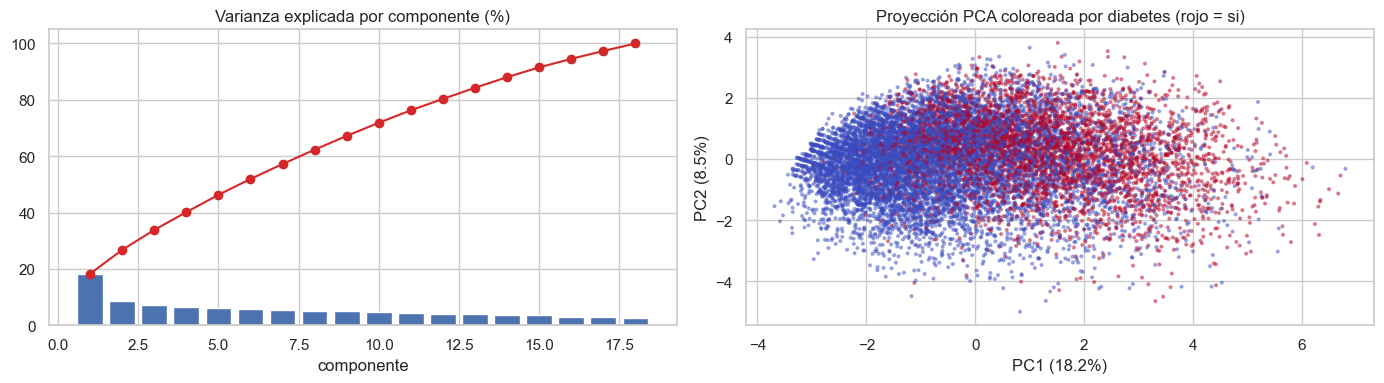

Varianza acumulada con 2 componentes: 26.7%  |  con 5: 46.3%


In [47]:
# Variables de la encuesta sin los objetivos, con los nulos rellenos con la mediana (solo para este análisis)
X_cl = df.drop(columns=[OBJ_CLF, OBJ_REG]).astype(float)
X_cl = X_cl.fillna(X_cl.median())

# Winsorizo el IMC al percentil 99, como propuse en el apartado 6
X_cl["imc"] = X_cl["imc"].clip(upper=X_cl["imc"].quantile(0.99))

# Estandarizo (media 0, desviación 1), porque el PCA es sensible a la escala, como vimos en la PLD2
Xs = StandardScaler().fit_transform(X_cl)

# PCA con todas las componentes para ver cuánta varianza explica cada una
pca = PCA(random_state=SEMILLA).fit(Xs)
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# Varianza explicada por componente (barras) y acumulada (línea roja)
axes[0].bar(range(1, len(var) + 1), var * 100)
axes[0].plot(range(1, len(var) + 1), np.cumsum(var) * 100, "o-", c="tab:red")
axes[0].set_title("Varianza explicada por componente (%)")
axes[0].set_xlabel("componente")

# Proyección de los pacientes sobre las dos primeras componentes, coloreada por diabetes
Z = pca.transform(Xs)[:, :2]
axes[1].scatter(Z[:, 0], Z[:, 1], c=df[OBJ_CLF].astype(int), cmap="coolwarm", s=4, alpha=0.4)
axes[1].set_xlabel(f"PC1 ({var[0] * 100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var[1] * 100:.1f}%)")
axes[1].set_title("Proyección PCA coloreada por diabetes (rojo = si)")
plt.tight_layout()
plt.show()

print(f"Varianza acumulada con 2 componentes: {var[:2].sum() * 100:.1f}%  |  con 5: {var[:5].sum() * 100:.1f}%")

In [48]:
# Cargas de cada variable en las tres primeras componentes, para poder interpretarlas
cargas = pd.DataFrame(pca.components_[:3].T, index=X_cl.columns, columns=["PC1", "PC2", "PC3"])
cargas.sort_values("PC1", key=abs, ascending=False).round(2)

,PC1,PC2,PC3
salud_general,0.41,-0.07,-0.07
dificultad_caminar,0.36,-0.05,-0.19
nivel_ingresos,-0.33,0.22,0.21
presion_alta,0.31,0.31,0.11
nivel_educativo,-0.28,0.21,0.01
actividad_fisica,-0.26,0.18,-0.05
enfermedad_cardiaca,0.25,0.24,0.06
colesterol_alto,0.24,0.34,0.13
imc,0.22,-0.10,0.00
grupo_edad,0.22,0.47,0.01


La varianza está bastante repartida entre muchas componentes (las dos primeras explican solo un 27 %), lo que es normal con tantas variables binarias. En la proyección no se ven grupos separados a simple vista, sino una nube continua. Es decir, **no hay clústeres "naturales" muy marcados**, y los perfiles que salgan serán más bien una forma útil de partir la población que grupos totalmente separados.

Mirando las cargas, la **PC1** es básicamente un eje de **mala salud** (salud general, dificultad para caminar, presión alta, enfermedad cardíaca, menos ingresos y estudios). La **PC2** recoge sobre todo la **edad y los factores metabólicos** (presión, colesterol) junto con hábitos saludables (fruta, verdura) y menos días de mala salud mental, es decir, separa a la gente mayor que tiene riesgo metabólico pero se cuida y está bien anímicamente. Esto da pistas de cómo podrían interpretarse los grupos, por ejemplo "jóvenes sanos", "mayores con riesgo metabólico pero buena salud percibida" o "pacientes con mala salud y limitaciones".

De cara a la clusterización saco estas ideas:

- Conviene **elegir un subconjunto pequeño de variables con sentido clínico** (por ejemplo edad, IMC, presión, colesterol, salud general, actividad física, dificultad para caminar...) en lugar de usar todas, porque con tantas binarias de poca varianza los grupos se vuelven difíciles de explicar.
- Hay que **escalar** las variables (el IMC y los días tienen escalas muy distintas a las binarias) y recortar los valores extremos del IMC.
- Como la mayoría de variables son binarias u ordinales, además de K-Means merece la pena probar **K-Prototypes, clustering jerárquico con distancia de Gower** o un **Gaussian Mixture**. Para compararlos sirve el silhouette, pero sobre todo hay que mirar lo interpretables que son los perfiles.
- `diabetes` y `dias_salud_fisica_mala` se pueden dejar fuera del clustering y usarlas después para **describir** cada grupo (qué porcentaje de diabéticos tiene cada perfil, cuántos días de mala salud...), que es justo lo que le interesa al consorcio.

## 9. Registro de incidencias

Todas las incidencias se han ido registrando con `registra(...)` a medida que aparecían. Aquí está el registro completo.

In [49]:
# Paso la lista de incidencias a un dataframe para verla en tabla
registro = pd.DataFrame(INCIDENCIAS)
print(f"{len(registro)} incidencias registradas")
registro

22 incidencias registradas


,columna,tipo_incidencia,n_filas_afectadas,accion
0,dni,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
1,nombre,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
2,apellidos,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
3,direccion,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
4,telefono,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
5,email,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
6,num_historia_clinica,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
7,id_paciente_proy,columna_sin_valor_predictivo,12750,"Usado como índice, fuera de las variables de e..."
8,usuario_alta_datos,columna_sin_valor_predictivo,12750,Columna eliminada: columna de gestión interna ...
9,fumador,categoria_inconsistente,3200,Unificadas las variantes si/SI/True/1.0 y no/N...


In [50]:
# Resumen por tipo de incidencia
registro.groupby("tipo_incidencia")["n_filas_afectadas"].agg(["count", "sum"]).rename(
    columns={"count": "n_columnas", "sum": "filas_afectadas_total"})

,n_columnas,filas_afectadas_total
tipo_incidencia,,
atipico_extremo,1,109
categoria_inconsistente,4,12800
columna_sin_valor_predictivo,2,25500
dato_personal,7,89250
valor_ausente,8,3222


## 10. Exportación de los entregables

Igual que en la PLE1, lo ejecuto **al final**, con el registro completo y el dataset ya saneado. Se generan dos archivos: el registro de incidencias y el dataset limpio (sin imputar ni escalar, porque eso se hace dentro del pipeline de cada línea de trabajo).

In [51]:
# Compruebo que el registro tiene el formato correcto antes de exportar
assert len(registro), "No hay ninguna incidencia registrada"
assert list(registro.columns) == ["columna", "tipo_incidencia", "n_filas_afectadas", "accion"], \
    "Las columnas del registro no son las esperadas"
assert registro["tipo_incidencia"].isin(CATALOGO).all(), "Hay etiquetas fuera del catálogo"

# Y que el dataset limpio no ha perdido filas ni tiene binarias con más de dos valores
assert len(df) == len(crudo), "Se han perdido filas por el camino"
assert (df[COLS_BIN + ["sexo"]].nunique() == 2).all(), "Hay alguna binaria con más de dos valores"

# Exporto los dos archivos
registro.to_csv("incidencias.csv", index=False, encoding="utf-8")
df.to_csv("proy_diabetes_limpio.csv", encoding="utf-8")

print(f"incidencias.csv           {len(registro)} incidencias")
print(f"proy_diabetes_limpio.csv  {df.shape[0]} filas x {df.shape[1]} columnas")

incidencias.csv           22 incidencias
proy_diabetes_limpio.csv  12750 filas x 20 columnas


## 11. Conclusiones

**Jerarquía de los defectos encontrados**

- El más importante son las **binarias escritas de cuatro formas** (3.200 filas, un 25 % del dataset). Si no se hubiera corregido, cada una de esas variables se habría convertido en hasta ocho categorías distintas y los modelos habrían tratado `si` y `SI` como cosas diferentes.
- Después van las **columnas personales y de gestión**. No estropean el modelo de forma tan directa, pero dejarlas sería un riesgo de sobreajuste (y de protección de datos) sin ningún beneficio.
- Los **valores ausentes** y los **atípicos del IMC** son ruido menor: afectan a menos del 5,2 % de las filas por columna, no tienen relación con los objetivos y se resuelven con imputación y recorte dentro del pipeline.
- Del resto del catálogo (nulos centinela, duplicados, fechas, unidades, texto corrupto, filas desplazadas, fuga de información) no he encontrado nada.

**Decisiones de preprocesamiento**

| Problema | Dónde | Decisión |
|---|---|---|
| Datos personales ofuscados | `dni`, `nombre`, `apellidos`, `direccion`, `telefono`, `email`, `num_historia_clinica` | Eliminar |
| Identificador | `id_paciente_proy` | Usar solo como índice |
| Columna de gestión sin relación con los objetivos | `usuario_alta_datos` | Eliminar |
| Binarias con 4 codificaciones | `fumador`, `actividad_fisica`, `consume_fruta`, `dificultad_caminar` | Normalizar a 0/1 |
| Nulos en bloque (≤ 5,2 % por columna), no relacionados con los objetivos | 8 columnas | Imputar dentro del pipeline (mediana/moda o KNN) |
| IMC con cola larga (hasta 95) | `imc` | Mantener y winsorizar al p99 en modelos sensibles y clustering |
| Categorías con muy pocos casos | `nivel_educativo` (`sin estudios` = 7) | Agrupar con `primaria` si se usa one-hot |
| Respuestas repetidas | 140 filas con perfil idéntico y distinto id | Mantener (son personas distintas) |

**Sobre las líneas de trabajo**

- **Clasificación (`diabetes`)**: 33 % de positivos por el remuestreo, así que partición estratificada, métricas ROC-AUC/F1/recall y ajuste del umbral pensando en el cribado. Las variables más prometedoras son salud general, presión alta, IMC, edad, colesterol alto, dificultad para caminar, enfermedad cardíaca e ingresos. Las probabilidades del modelo **no** son poblacionales.
- **Regresión (`dias_salud_fisica_mala`)**: 60 % de ceros y un pico en 30, por lo que conviene probar modelos de dos etapas o Tweedie/Poisson además de los regresores clásicos, reportar MAE además de RMSE y recortar las predicciones a [0, 30]. Las variables clave son salud general, dificultad para caminar y días de mala salud mental.
- **Clusterización**: no hay grupos naturales muy separados, así que la clave estará en escoger pocas variables con sentido clínico, escalarlas y priorizar que los perfiles se puedan explicar por encima de las métricas internas.

**Limitaciones**

La principal es el remuestreo: como la muestra tiene un tercio de diabéticos a propósito, todas las tasas de este EDA (por ejemplo el 62 % de diabetes en obesidad III) sirven para comparar grupos entre sí, pero no son las tasas reales de la población. Además, los días de mala salud son autodeclarados y redondeados, así que la variable de regresión tiene un ruido que ningún modelo va a poder eliminar.

En conclusión, el dataset es bastante manejable una vez arreglados los problemas de codificación, y los resultados del EDA tienen sentido clínico, lo que da confianza en los datos. Hay que tener cuidado con una cosa: toda la imputación, escalado o selección de variables que "aprenda" algo de los datos debe ajustarse **solo con el train**, metiéndola dentro de un `Pipeline` de scikit-learn, porque si no estaríamos colando información del test en el entrenamiento y las métricas saldrían más optimistas de lo que son.